# ECG Arrhythmia Classification

Classifying individual heartbeats into four AAMI classes (N / S / V / F) from the MIT-BIH
Arrhythmia Database, using classical machine learning only.

Every result in this notebook is written to `results/tables/` as CSV and `results/figures/`
as PNG. The final cells build the README and push the whole project to GitHub.

## 1. Setup

In [1]:
!pip -q install wfdb pywavelets scipy pyarrow tqdm scikit-learn imbalanced-learn > /dev/null 2>&1

import os, time, json, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import wfdb, pywt
from scipy.signal import butter, filtfilt, medfilt
from scipy.stats import skew, kurtosis
from tqdm.auto import tqdm

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     StratifiedGroupKFold, GroupKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             balanced_accuracy_score, precision_recall_fscore_support,
                             accuracy_score, log_loss, cohen_kappa_score)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
DATA    = "/content/drive/MyDrive/ecg_mitbih"
PROJ    = os.path.join(DATA, "project")
FIG     = os.path.join(PROJ, "results", "figures")
TAB     = os.path.join(PROJ, "results", "tables")
RES     = os.path.join(PROJ, "results")
NBDIR   = os.path.join(PROJ, "notebook")
SIG_DIR = os.path.join(DATA, "signals")
FEAT    = os.path.join(DATA, "ecg_features.parquet")

for d in (FIG, TAB, RES, NBDIR, SIG_DIR):
    os.makedirs(d, exist_ok=True)

FS, SEED, CAP = 360, 42, 25000
REBUILD_FEATURES = False

CLASSES    = ["N", "S", "V", "F"]
CLASS_NAME = {"N": "Normal", "S": "Supraventricular", "V": "Ventricular", "F": "Fusion"}
CLASS_COL  = {"N": "#2F3C7E", "S": "#C87A2A", "V": "#990011", "F": "#5F7A52"}
SPLIT_COL  = {"random": "#8FA8D8", "inter-patient": "#990011"}

AAMI = {"N": ["N","L","R","e","j"], "S": ["A","a","J","S"],
        "V": ["V","E"], "F": ["F"], "Q": ["/","f","Q"]}
SYM2AAMI  = {s: k for k, v in AAMI.items() for s in v}
BEAT_SYMS = set(SYM2AAMI)

DS1 = ["101","106","108","109","112","114","115","116","118","119","122",
       "124","201","203","205","207","208","209","215","220","223","230"]
DS2 = ["100","103","105","111","113","117","121","123","200","202","210",
       "212","213","214","219","221","222","228","231","232","233","234"]
RECORDS = DS1 + DS2
PACED   = ["102","104","107","217"]

RR_NAMES   = ["pre_rr","post_rr","local_rr","global_rr",
              "pre_over_local","pre_over_global","post_over_pre","local_over_global"]
STAT_NAMES = ["skew","kurt","energy","rpeak_amp","min_amp","qrs_width"]

RESULTS = {}

def save_table(df, name, index=False, show=True):
    df.to_csv(os.path.join(TAB, name + ".csv"), index=index)
    RESULTS[name] = df
    if show:
        print(df.to_string(index=index))
    return df

def save_fig(fig, name, show=True):
    fig.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight", facecolor="white")
    if show:
        plt.show()
    else:
        plt.close(fig)

print("project :", PROJ)
print("records :", len(RECORDS), "| excluded:", PACED, "| classes:", CLASSES)

project : /content/drive/MyDrive/ecg_mitbih/project
records : 44 | excluded: ['102', '104', '107', '217'] | classes: ['N', 'S', 'V', 'F']


## 2. Data collection

In [3]:
def load_signal(rec):
    cache = os.path.join(SIG_DIR, rec + ".npy")
    meta  = os.path.join(SIG_DIR, rec + "_lead.txt")
    if os.path.exists(cache):
        return np.load(cache), open(meta).read().strip()
    r = wfdb.rdrecord(rec, pn_dir="mitdb")
    ch = r.sig_name.index("MLII") if "MLII" in r.sig_name else 0
    sig = r.p_signal[:, ch].astype(np.float32)
    np.save(cache, sig)
    open(meta, "w").write(r.sig_name[ch])
    return sig, r.sig_name[ch]

t0 = time.time()
leads = {rec: load_signal(rec)[1] for rec in tqdm(RECORDS, desc="records")}
r0 = wfdb.rdrecord("100", pn_dir="mitdb")

source = pd.DataFrame([
    {"property": "Database",        "value": "MIT-BIH Arrhythmia Database"},
    {"property": "Source",          "value": "PhysioNet (open access)"},
    {"property": "Recordings used", "value": f"{len(RECORDS)} of 48"},
    {"property": "Excluded (paced)","value": ", ".join(PACED)},
    {"property": "Duration each",   "value": f"{r0.p_signal.shape[0]/FS/60:.1f} min"},
    {"property": "Sampling rate",   "value": f"{FS} Hz"},
    {"property": "Samples/record",  "value": f"{r0.p_signal.shape[0]:,}"},
    {"property": "Lead used",       "value": ", ".join(f"{k} x{v}" for k, v in pd.Series(leads).value_counts().items())},
    {"property": "Load time",       "value": f"{time.time()-t0:.0f} s"},
])
save_table(source, "01_data_source")

records:   0%|          | 0/44 [00:00<?, ?it/s]

        property                       value
        Database MIT-BIH Arrhythmia Database
          Source     PhysioNet (open access)
 Recordings used                    44 of 48
Excluded (paced)          102, 104, 107, 217
   Duration each                    30.1 min
   Sampling rate                      360 Hz
  Samples/record                     650,000
       Lead used                    MLII x44
       Load time                        25 s


,property,value
0,Database,MIT-BIH Arrhythmia Database
1,Source,PhysioNet (open access)
2,Recordings used,44 of 48
3,Excluded (paced),"102, 104, 107, 217"
4,Duration each,30.1 min
5,Sampling rate,360 Hz
6,Samples/record,"650,000"
7,Lead used,MLII x44
8,Load time,25 s


## 3. Data exploration

In [4]:
rows = []
for rec in tqdm(RECORDS, desc="annotations"):
    a = wfdb.rdann(rec, "atr", pn_dir="mitdb")
    for s, y in zip(a.sample, a.symbol):
        if y in BEAT_SYMS:
            rows.append({"record": rec, "symbol": y, "aami": SYM2AAMI[y],
                         "split": "DS1" if rec in DS1 else "DS2"})
ann = pd.DataFrame(rows)

sym = (ann["symbol"].value_counts().rename_axis("symbol").reset_index(name="beats"))
sym["aami"] = sym["symbol"].map(SYM2AAMI)
save_table(sym, "02_raw_symbols")

annotations:   0%|          | 0/44 [00:00<?, ?it/s]

symbol  beats aami
     N  74546    N
     L   8075    N
     R   7259    N
     V   6903    V
     A   2546    S
     F    803    F
     j    229    N
     a    150    S
     E    106    V
     J     83    S
     e     16    N
     Q     15    Q
     S      2    S


,symbol,beats,aami
0,N,74546,N
1,L,8075,N
2,R,7259,N
3,V,6903,V
4,A,2546,S
5,F,803,F
6,j,229,N
7,a,150,S
8,E,106,V
9,J,83,S


class          meaning  beats  share_pct  ratio_to_N
    N           Normal  90125      89.48           1
    S Supraventricular   2781       2.76          32
    V      Ventricular   7009       6.96          13
    F           Fusion    803       0.80         112


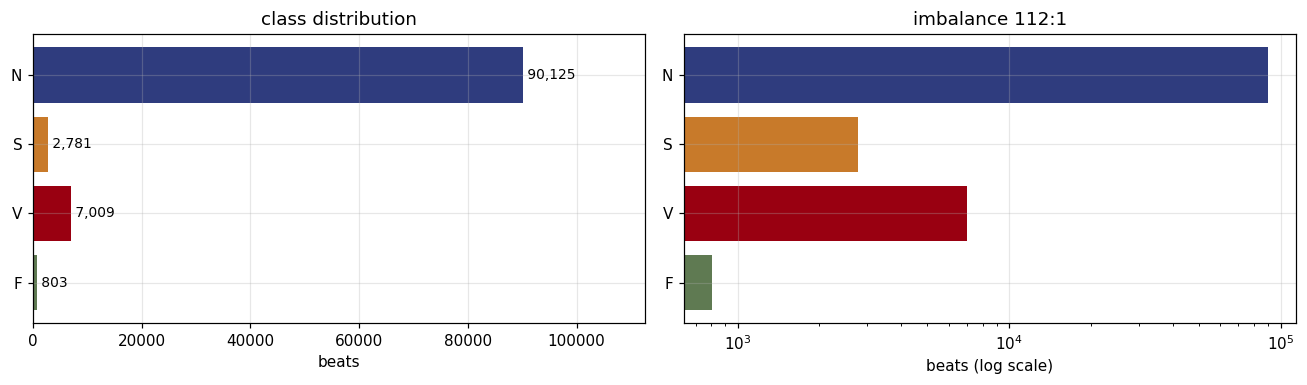

In [5]:
vc = ann[ann.aami.isin(CLASSES)]["aami"].value_counts().reindex(CLASSES)
dist = pd.DataFrame({
    "class": CLASSES,
    "meaning": [CLASS_NAME[c] for c in CLASSES],
    "beats": vc.values,
    "share_pct": (vc.values / vc.sum() * 100).round(2),
})
dist["ratio_to_N"] = (vc.max() / vc.values).round(0).astype(int)
save_table(dist, "03_class_distribution")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].barh(dist["class"], dist["beats"], color=[CLASS_COL[c] for c in CLASSES])
for i, v in enumerate(dist["beats"]):
    ax[0].text(v, i, f" {v:,}", va="center", fontsize=9)
ax[0].set_xlabel("beats"); ax[0].set_title("class distribution")
ax[0].invert_yaxis(); ax[0].set_xlim(0, dist["beats"].max()*1.25)

ax[1].barh(dist["class"], dist["beats"], color=[CLASS_COL[c] for c in CLASSES])
ax[1].set_xscale("log"); ax[1].set_xlabel("beats (log scale)")
ax[1].set_title(f"imbalance {dist['beats'].max()//dist['beats'].min()}:1")
ax[1].invert_yaxis()
plt.tight_layout()
save_fig(fig, "01_class_distribution")

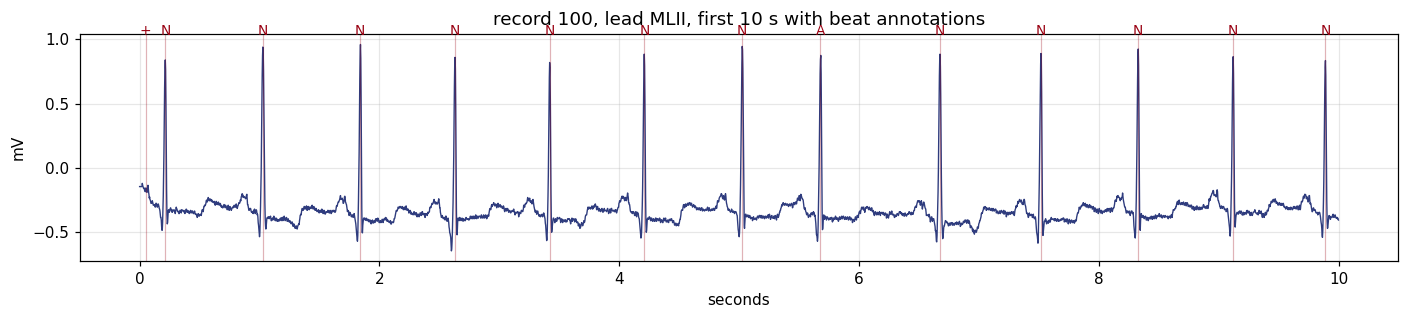

In [6]:
sig = load_signal("100")[0]
a   = wfdb.rdann("100", "atr", pn_dir="mitdb")
seg, t = sig[:10*FS], np.arange(10*FS)/FS
m = a.sample < 10*FS
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(t, seg, lw=0.9, color="#2F3C7E")
for p, s in zip(a.sample[m], np.array(a.symbol)[m]):
    ax.axvline(p/FS, color="#990011", alpha=0.3, lw=0.8)
    ax.text(p/FS, seg.max()*1.08, s, ha="center", fontsize=9, color="#990011")
ax.set_xlabel("seconds"); ax.set_ylabel("mV")
ax.set_title("record 100, lead MLII, first 10 s with beat annotations")
plt.tight_layout()
save_fig(fig, "02_signal_annotated")

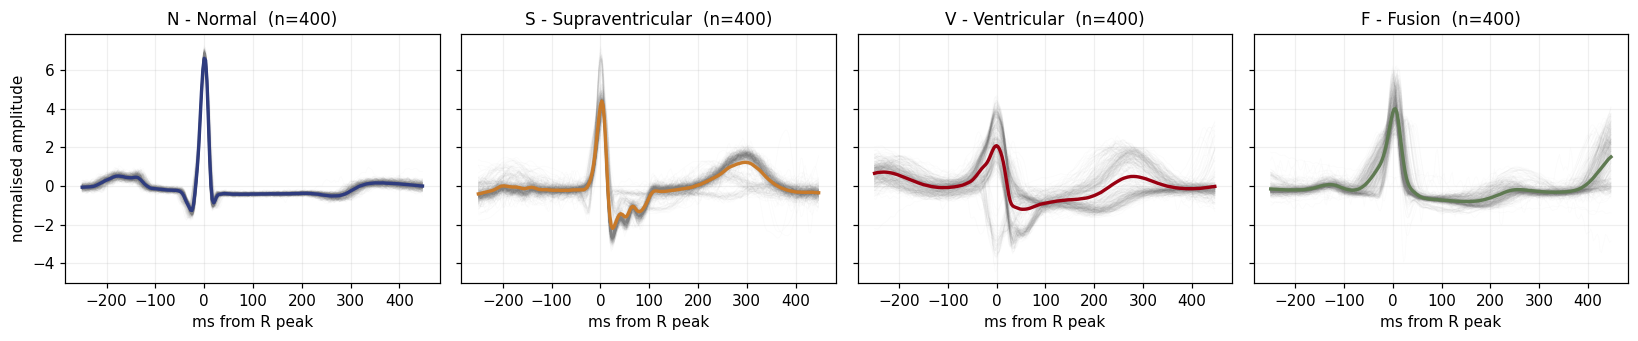

In [7]:
PRE, POST = int(0.25*FS), int(0.45*FS)
WIN = PRE + POST

collected = {c: [] for c in CLASSES}
for rec in ["100","106","200","208","213","232"]:
    s_, a_ = load_signal(rec)[0], wfdb.rdann(rec, "atr", pn_dir="mitdb")
    for samp, symv in zip(a_.sample, a_.symbol):
        if symv not in BEAT_SYMS:
            continue
        c = SYM2AAMI[symv]
        if c not in CLASSES or len(collected[c]) >= 400:
            continue
        if samp-PRE < 0 or samp+POST >= len(s_):
            continue
        b = s_[samp-PRE:samp+POST]
        collected[c].append((b - b.mean())/(b.std()+1e-9))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, c in zip(axes, CLASSES):
    arr = np.array(collected[c])
    tt = (np.arange(arr.shape[1]) - PRE)/FS*1000
    ax.plot(tt, arr.T, color="gray", alpha=0.03, lw=0.5)
    ax.plot(tt, arr.mean(0), color=CLASS_COL[c], lw=2.2)
    ax.set_title(f"{c} - {CLASS_NAME[c]}  (n={len(arr)})", fontsize=11)
    ax.set_xlabel("ms from R peak"); ax.grid(alpha=0.2)
axes[0].set_ylabel("normalised amplitude")
plt.tight_layout()
save_fig(fig, "03_beat_morphology")

## 4. Data cleaning

Baseline wander removed with stacked median filters (200 ms then 600 ms), then a zero-phase
Butterworth bandpass at 0.5-40 Hz.

In [8]:
B, A = butter(3, [0.5/(FS/2), 40/(FS/2)], btype="band")

def clean(x):
    base = medfilt(medfilt(x, int(0.2*FS)|1), int(0.6*FS)|1)
    return filtfilt(B, A, x - base).astype(np.float32)

steps = pd.DataFrame([
    {"step": "Baseline removal", "method": "median filter 200 ms then 600 ms",
     "removes": "respiration drift"},
    {"step": "Bandpass",         "method": "Butterworth order 3, 0.5-40 Hz, zero phase",
     "removes": "power-line hum, muscle noise"},
    {"step": "Segmentation",     "method": f"{PRE} samples before R, {POST} after ({WIN} total, {WIN/FS*1000:.0f} ms)",
     "removes": "inter-beat gaps"},
    {"step": "Normalisation",    "method": "per beat, zero mean unit variance",
     "removes": "amplitude differences between recordings"},
])
save_table(steps, "04_preprocessing_steps")

            step                                             method                                  removes
Baseline removal                   median filter 200 ms then 600 ms                        respiration drift
        Bandpass         Butterworth order 3, 0.5-40 Hz, zero phase             power-line hum, muscle noise
    Segmentation 90 samples before R, 162 after (252 total, 700 ms)                          inter-beat gaps
   Normalisation                  per beat, zero mean unit variance amplitude differences between recordings


,step,method,removes
0,Baseline removal,median filter 200 ms then 600 ms,respiration drift
1,Bandpass,"Butterworth order 3, 0.5-40 Hz, zero phase","power-line hum, muscle noise"
2,Segmentation,"90 samples before R, 162 after (252 total, 700...",inter-beat gaps
3,Normalisation,"per beat, zero mean unit variance",amplitude differences between recordings


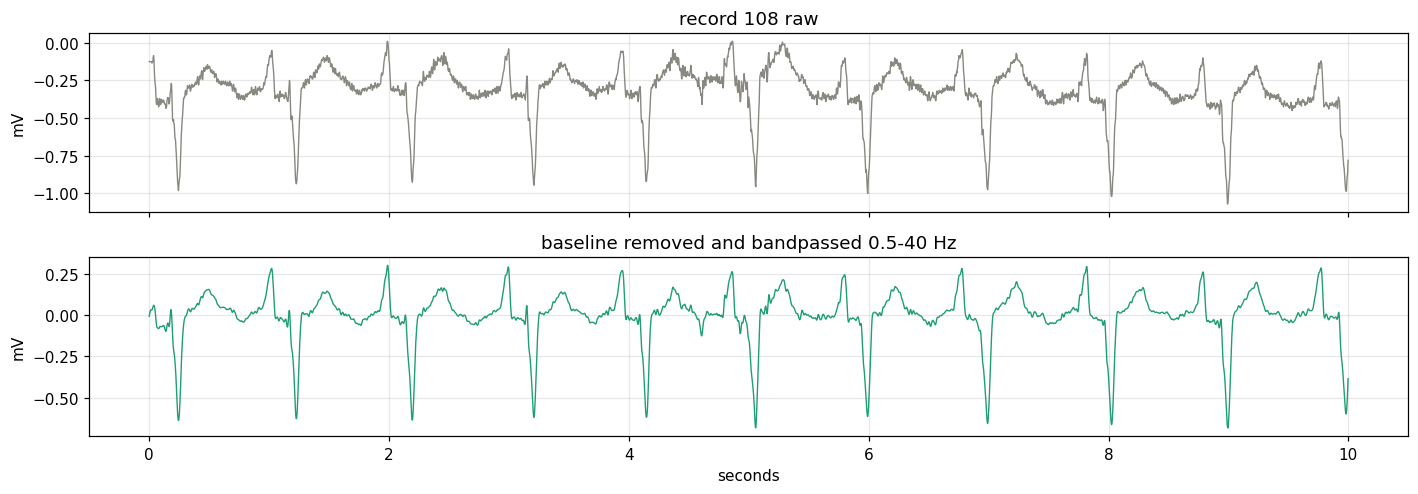

In [9]:
raw = load_signal("108")[0]
cl  = clean(raw)
fig, ax = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True)
tt = np.arange(10*FS)/FS
ax[0].plot(tt, raw[:10*FS], lw=0.9, color="#888780")
ax[0].set_title("record 108 raw"); ax[0].set_ylabel("mV")
ax[1].plot(tt, cl[:10*FS], lw=0.9, color="#1D9E75")
ax[1].set_title("baseline removed and bandpassed 0.5-40 Hz")
ax[1].set_xlabel("seconds"); ax[1].set_ylabel("mV")
plt.tight_layout()
save_fig(fig, "04_cleaning")

## 5. Feature engineering

In [10]:
def segment(rec):
    x = clean(load_signal(rec)[0])
    a = wfdb.rdann(rec, "atr", pn_dir="mitdb")
    samp = np.array([s for s, y in zip(a.sample, a.symbol) if y in BEAT_SYMS])
    syms = np.array([y for y in a.symbol if y in BEAT_SYMS])
    rr   = np.diff(samp)/FS
    grr  = float(np.median(rr)) if len(rr) else 1.0
    out = []
    for i, (s, y) in enumerate(zip(samp, syms)):
        c = SYM2AAMI[y]
        if c not in CLASSES or s-PRE < 0 or s+POST >= len(x):
            continue
        b = x[s-PRE:s+POST]
        b = (b - b.mean())/(b.std()+1e-9)
        pre  = rr[i-1] if i >= 1 else grr
        post = rr[i]   if i < len(rr) else grr
        lo   = max(0, i-10)
        loc  = float(np.mean(rr[lo:i])) if i > lo else grr
        out.append((b, (pre, post, loc, grr), c, rec, i, y))
    return out

def extract(b, rr):
    f = {}
    pre, post, loc, glob = rr
    f["pre_rr"], f["post_rr"], f["local_rr"], f["global_rr"] = pre, post, loc, glob
    f["pre_over_local"]    = pre /(loc +1e-9)
    f["pre_over_global"]   = pre /(glob+1e-9)
    f["post_over_pre"]     = post/(pre +1e-9)
    f["local_over_global"] = loc /(glob+1e-9)
    ds = np.interp(np.linspace(0, len(b)-1, 32), np.arange(len(b)), b)
    for i, v in enumerate(ds):
        f["morph%d" % i] = float(v)
    for i, c in enumerate(pywt.wavedec(b, "db4", level=4)):
        f["w%d_energy" % i] = float(np.sum(c**2))
        f["w%d_std" % i]    = float(np.std(c))
        f["w%d_mean" % i]   = float(np.mean(c))
    f["skew"], f["kurt"] = float(skew(b)), float(kurtosis(b))
    f["energy"], f["rpeak_amp"] = float(np.sum(b**2)), float(b.max())
    f["min_amp"] = float(b.min())
    f["qrs_width"] = float(np.sum(np.abs(b) > 0.5)/FS)
    return f

catalogue = pd.DataFrame([
    {"family": "Timing (RR)", "n": 8,
     "features": "pre_rr, post_rr, local_rr, global_rr + 4 ratios",
     "purpose": "is this beat early or late relative to the patient's own rhythm"},
    {"family": "Beat shape", "n": 32,
     "features": "morph0 .. morph31",
     "purpose": "the 700 ms curve resampled to 32 points"},
    {"family": "Wavelet", "n": 15,
     "features": "w0..w4 energy, std, mean (db4, level 4)",
     "purpose": "energy at five frequency scales; wide beats shift energy to coarse bands"},
    {"family": "Statistics", "n": 6,
     "features": "skew, kurt, energy, rpeak_amp, min_amp, qrs_width",
     "purpose": "sharpness, asymmetry and a direct width measurement"},
    {"family": "TOTAL", "n": 61, "features": "", "purpose": ""},
])
save_table(catalogue, "05_feature_catalogue")

     family  n                                          features                                                                  purpose
Timing (RR)  8   pre_rr, post_rr, local_rr, global_rr + 4 ratios          is this beat early or late relative to the patient's own rhythm
 Beat shape 32                                 morph0 .. morph31                                  the 700 ms curve resampled to 32 points
    Wavelet 15           w0..w4 energy, std, mean (db4, level 4) energy at five frequency scales; wide beats shift energy to coarse bands
 Statistics  6 skew, kurt, energy, rpeak_amp, min_amp, qrs_width                      sharpness, asymmetry and a direct width measurement
      TOTAL 61                                                                                                                           


,family,n,features,purpose
0,Timing (RR),8,"pre_rr, post_rr, local_rr, global_rr + 4 ratios",is this beat early or late relative to the pat...
1,Beat shape,32,morph0 .. morph31,the 700 ms curve resampled to 32 points
2,Wavelet,15,"w0..w4 energy, std, mean (db4, level 4)",energy at five frequency scales; wide beats sh...
3,Statistics,6,"skew, kurt, energy, rpeak_amp, min_amp, qrs_width","sharpness, asymmetry and a direct width measur..."
4,TOTAL,61,,


In [11]:
if os.path.exists(FEAT) and not REBUILD_FEATURES:
    feat = pd.read_parquet(FEAT)
    print("loaded cached features:", feat.shape)
else:
    rows, t0 = [], time.time()
    for rec in tqdm(RECORDS, desc="features"):
        for b, rr, c, r, idx, symv in segment(rec):
            try:
                f = extract(b, rr)
            except Exception:
                continue
            f.update(record=r, beat_idx=idx, symbol=symv, aami=c,
                     split="DS1" if r in DS1 else "DS2")
            rows.append(f)
    feat = pd.DataFrame(rows)
    feat.to_parquet(FEAT, index=False)
    print("extracted %d beats in %.0f s" % (len(feat), time.time()-t0))

META     = ["record","beat_idx","symbol","aami","split"]
FEATURES = [c for c in feat.columns if c not in META]
print("beats:", len(feat), "| features designed:", len(FEATURES))

loaded cached features: (100679, 66)
beats: 100679 | features designed: 61


## 6. Data validation

In [12]:
feat[FEATURES] = feat[FEATURES].replace([np.inf, -np.inf], np.nan)
nan_before = int(feat[FEATURES].isna().sum().sum())
feat[FEATURES] = feat[FEATURES].fillna(feat[FEATURES].median())

overlap = len(set(feat[feat.split=="DS1"].record) & set(feat[feat.split=="DS2"].record))
checks = pd.DataFrame([
    {"check": "Beats extracted",            "value": f"{len(feat):,}", "status": "ok"},
    {"check": "Records",                    "value": feat["record"].nunique(), "status": "ok"},
    {"check": "Features designed",          "value": len(FEATURES), "status": "ok"},
    {"check": "Missing or infinite values", "value": nan_before,
     "status": "ok" if nan_before == 0 else "imputed with median"},
    {"check": "Constant features",          "value": int((feat[FEATURES].nunique() <= 1).sum()), "status": "ok"},
    {"check": "Classes present",            "value": ", ".join(sorted(feat['aami'].unique())), "status": "ok"},
    {"check": "Patients in both DS1 and DS2","value": overlap,
     "status": "ok" if overlap == 0 else "LEAK"},
])
save_table(checks, "06_data_validation")
assert overlap == 0

                       check      value status
             Beats extracted    100,679     ok
                     Records         44     ok
           Features designed         61     ok
  Missing or infinite values          0     ok
           Constant features          0     ok
             Classes present F, N, S, V     ok
Patients in both DS1 and DS2          0     ok


class split  beats  records top_record  top_beats  top_share_pct  top3_share_pct
    S   DS1    944       16        209        383           40.6            65.5
    S   DS2   1837       16        232       1382           75.2            89.6
    F   DS1    414       10        208        372           89.9            95.9
    F   DS2    388        7        213        362           93.3            98.7


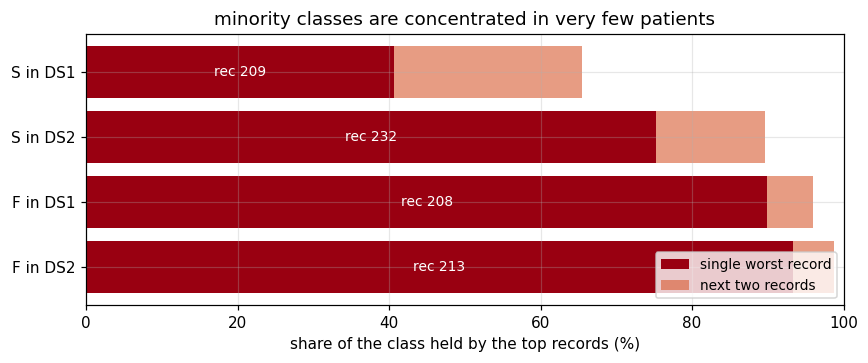

In [13]:
conc = []
for c in ["S", "F"]:
    for sp in ["DS1", "DS2"]:
        s = feat[(feat.aami==c) & (feat.split==sp)]["record"].value_counts()
        if len(s) == 0:
            continue
        conc.append({"class": c, "split": sp, "beats": int(s.sum()), "records": len(s),
                     "top_record": s.index[0], "top_beats": int(s.iloc[0]),
                     "top_share_pct": round(100*s.iloc[0]/s.sum(), 1),
                     "top3_share_pct": round(100*s.head(3).sum()/s.sum(), 1)})
conc = pd.DataFrame(conc)
save_table(conc, "07_minority_concentration")

fig, ax = plt.subplots(figsize=(8, 3.4))
lbl = conc["class"] + " in " + conc["split"]
ax.barh(lbl, conc["top_share_pct"], color="#990011", label="single worst record")
ax.barh(lbl, conc["top3_share_pct"] - conc["top_share_pct"],
        left=conc["top_share_pct"], color="#D85A30", alpha=0.6, label="next two records")
for i, r in conc.iterrows():
    ax.text(r["top_share_pct"]/2, i, f"rec {r['top_record']}", va="center", ha="center",
            color="white", fontsize=9)
ax.set_xlabel("share of the class held by the top records (%)")
ax.set_xlim(0, 100); ax.legend(loc="lower right", fontsize=9)
ax.set_title("minority classes are concentrated in very few patients")
ax.invert_yaxis(); plt.tight_layout()
save_fig(fig, "05_minority_concentration")

## 7. Feature selection

In [14]:
corr    = feat[FEATURES].corr().abs()
upper   = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
dropped = [c for c in upper.columns if (upper[c] > 0.97).any()]
FEATURES = [c for c in FEATURES if c not in dropped]

FAMILIES = {
    "rr":      [c for c in FEATURES if c in RR_NAMES],
    "morph":   [c for c in FEATURES if c.startswith("morph")],
    "wavelet": [c for c in FEATURES if c[0] == "w" and "_" in c],
    "stats":   [c for c in FEATURES if c in STAT_NAMES],
}
FAMILIES["ALL"] = FEATURES
assigned = set().union(*[set(v) for k, v in FAMILIES.items() if k != "ALL"])
missing  = [c for c in FEATURES if c not in assigned]
assert not missing, missing

sel = pd.DataFrame([{"family": k, "kept": len(v)} for k, v in FAMILIES.items() if k != "ALL"])
sel.loc[len(sel)] = ["TOTAL kept", len(FEATURES)]
sel.loc[len(sel)] = ["dropped (corr > 0.97)", len(dropped)]
save_table(sel, "08_feature_selection")
print()
print("dropped:", dropped)

X_all = feat[FEATURES].values
y_all = feat["aami"].values
g_all = feat["record"].values

               family  kept
                   rr     8
                morph    32
              wavelet    13
                stats     6
           TOTAL kept    59
dropped (corr > 0.97)     2

dropped: ['w0_std', 'w4_std']


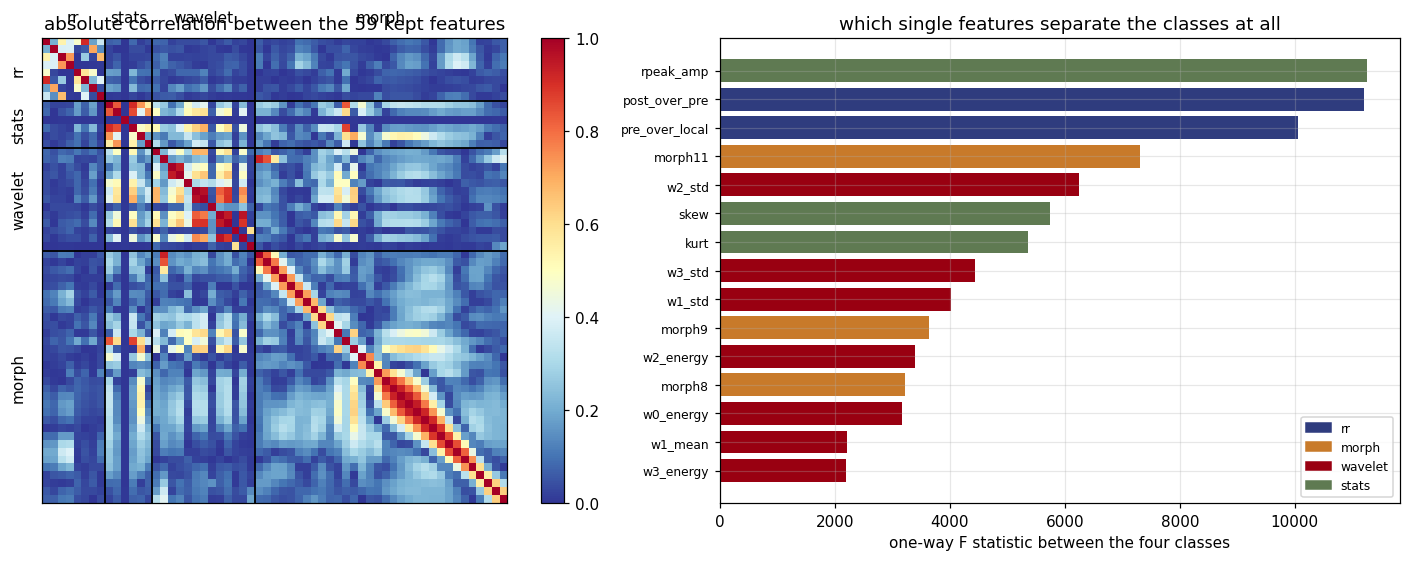

       feature  f_statistic  family
     rpeak_amp     11257.25   stats
 post_over_pre     11210.38      rr
pre_over_local     10060.98      rr
       morph11      7303.28   morph
        w2_std      6251.06 wavelet
          skew      5740.21   stats
          kurt      5357.44   stats
        w3_std      4440.11 wavelet
        w1_std      4014.33 wavelet
        morph9      3642.69   morph


In [15]:
ORD = FAMILIES["rr"] + FAMILIES["stats"] + FAMILIES["wavelet"] + FAMILIES["morph"]
C = feat[ORD].corr().abs().values
bounds, acc = [], 0
for k in ["rr", "stats", "wavelet", "morph"]:
    acc += len(FAMILIES[k]); bounds.append(acc)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
im = ax[0].imshow(C, cmap="RdYlBu_r", vmin=0, vmax=1)
for b in bounds[:-1]:
    ax[0].axhline(b-0.5, color="black", lw=1.2)
    ax[0].axvline(b-0.5, color="black", lw=1.2)
mids = [0] + bounds
for i, k in enumerate(["rr", "stats", "wavelet", "morph"]):
    m = (mids[i] + mids[i+1])/2 - 0.5
    ax[0].text(m, -2.5, k, ha="center", fontsize=10)
    ax[0].text(-2.5, m, k, va="center", ha="right", fontsize=10, rotation=90)
ax[0].set_xticks([]); ax[0].set_yticks([]); ax[0].grid(False)
ax[0].set_title("absolute correlation between the %d kept features" % len(FEATURES))
fig.colorbar(im, ax=ax[0], fraction=0.046)

fstat = {}
for c in FEATURES:
    groups = [feat[feat.aami == k][c].values for k in CLASSES]
    gm = feat[c].mean()
    between = sum(len(g)*(g.mean()-gm)**2 for g in groups)/(len(CLASSES)-1)
    within  = sum(((g-g.mean())**2).sum() for g in groups)/(len(feat)-len(CLASSES))
    fstat[c] = between/(within+1e-12)
fs = (pd.Series(fstat).sort_values(ascending=False).rename("f_statistic")
        .reset_index().rename(columns={"index": "feature"}))
fs["family"] = fs["feature"].map({c: k for k, v in FAMILIES.items() if k != "ALL" for c in v})
fs["f_statistic"] = fs["f_statistic"].round(2)
save_table(fs.head(15), "09_univariate_separation", show=False)

FAM_C = {"rr": "#2F3C7E", "morph": "#C87A2A", "wavelet": "#990011", "stats": "#5F7A52"}
tp = fs.head(15).iloc[::-1]
ax[1].barh(tp["feature"], tp["f_statistic"], color=[FAM_C[f] for f in tp["family"]])
ax[1].set_xlabel("one-way F statistic between the four classes")
ax[1].set_title("which single features separate the classes at all")
ax[1].tick_params(axis="y", labelsize=8)
hs = [plt.Rectangle((0,0),1,1,color=FAM_C[f]) for f in FAM_C]
ax[1].legend(hs, list(FAM_C), fontsize=8, loc="lower right")
plt.tight_layout()
save_fig(fig, "06_feature_correlation")

print(fs.head(10).to_string(index=False))

## 8. Validation strategy

In [16]:
def split_random(test_size=0.25):
    return train_test_split(np.arange(len(feat)), test_size=test_size,
                            stratify=y_all, random_state=SEED)

def split_interpatient():
    return (np.where(feat["split"].values == "DS1")[0],
            np.where(feat["split"].values == "DS2")[0])

def subsample(idx, cap=CAP):
    if len(idx) <= cap:
        return idx
    keep, _ = train_test_split(np.arange(len(idx)), train_size=cap,
                               stratify=y_all[idx], random_state=SEED)
    return idx[keep]

prot = []
for name, fn in [("random", split_random), ("inter-patient", split_interpatient)]:
    tr, te = fn()
    prot.append({"protocol": name, "train_beats": len(tr), "test_beats": len(te),
                 "train_patients": len(set(g_all[tr])), "test_patients": len(set(g_all[te])),
                 "patients_in_both": len(set(g_all[tr]) & set(g_all[te]))})
prot = pd.DataFrame(prot)
save_table(prot, "10_validation_protocols")

tr_i, te_i = split_interpatient()
assert not (set(g_all[tr_i]) & set(g_all[te_i]))

     protocol  train_beats  test_beats  train_patients  test_patients  patients_in_both
       random        75509       25170              44             44                44
inter-patient        50994       49685              22             22                 0


## 9. Model training

Four classical algorithms, each a different kind of decision boundary. Hyperparameters are
chosen by grid search with `StratifiedGroupKFold` grouped by patient, so no patient appears
on both sides of any inner fold.

In [17]:
MODEL_DESC = pd.DataFrame([
    {"model": "logreg", "name": "Logistic regression", "boundary": "one straight boundary",
     "role": "baseline every other model must beat"},
    {"model": "linsvm", "name": "Linear SVM", "boundary": "straight, widest margin",
     "role": "tests whether better placement helps"},
    {"model": "rbfsvm", "name": "RBF SVM", "boundary": "curved",
     "role": "tests whether curvature helps"},
    {"model": "rf", "name": "Random forest", "boundary": "staircase of thresholds",
     "role": "ensemble, and reports feature importance"},
])
save_table(MODEL_DESC, "11_models")

def make_models(n):
    m = {
      "logreg": (Pipeline([("sc", StandardScaler()),
                 ("clf", LogisticRegression(max_iter=3000, class_weight="balanced",
                                            random_state=SEED))]),
                 {"clf__C": [0.01, 0.1, 1, 10]}),
      "linsvm": (Pipeline([("sc", StandardScaler()),
                 ("clf", LinearSVC(class_weight="balanced", max_iter=5000,
                                   random_state=SEED))]),
                 {"clf__C": [0.01, 0.1, 1]}),
      "rf":     (Pipeline([("clf", RandomForestClassifier(n_estimators=300,
                           class_weight="balanced_subsample", n_jobs=-1,
                           random_state=SEED))]),
                 {"clf__max_depth": [6, 8, 12, None], "clf__min_samples_leaf": [1, 5]}),
    }
    if n <= CAP:
        m["rbfsvm"] = (Pipeline([("sc", StandardScaler()),
                       ("clf", SVC(class_weight="balanced", random_state=SEED))]),
                       {"clf__C": [1, 10], "clf__gamma": ["scale"]})
    return m

GRID_LOG, RES_MODELS = {}, {}

def run_split(key, title, tr, te):
    tr = subsample(tr)
    Xtr, ytr, gtr = X_all[tr], y_all[tr], g_all[tr]
    Xte, yte = X_all[te], y_all[te]
    print(f"\n{title}   train={len(ytr)}  test={len(yte)}")
    out = {}
    for name, (pipe, grid) in make_models(len(ytr)).items():
        t0 = time.time()
        cv = StratifiedGroupKFold(n_splits=min(3, len(set(gtr))))
        gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=-1,
                          return_train_score=True)
        gs.fit(Xtr, ytr, groups=gtr)
        GRID_LOG[(key, name)] = pd.DataFrame(gs.cv_results_)
        best = gs.best_estimator_
        pred = best.predict(Xte)
        out[name] = {"model": best, "pred": pred, "params": gs.best_params_,
                     "cv_f1": gs.best_score_, "train_pred": best.predict(Xtr),
                     "ytr": ytr, "secs": time.time()-t0,
                     "proba": best.predict_proba(Xte) if hasattr(best, "predict_proba") else None}
        print(f"  {name:<8} cv_f1={gs.best_score_:.4f}  {gs.best_params_}  ({time.time()-t0:.0f}s)")
    return {"results": out, "ytest": yte, "test_idx": te, "train_idx": tr}

tr, te = split_random()
RES_MODELS["random"] = run_split(
    "random", "RANDOM SPLIT - the same patient appears on both sides", tr, te)
tr, te = split_interpatient()
RES_MODELS["inter-patient"] = run_split(
    "inter-patient", "INTER-PATIENT SPLIT - DS1 trains, DS2 tests, no patient shared", tr, te)

 model                name                boundary                                     role
logreg Logistic regression   one straight boundary     baseline every other model must beat
linsvm          Linear SVM straight, widest margin     tests whether better placement helps
rbfsvm             RBF SVM                  curved            tests whether curvature helps
    rf       Random forest staircase of thresholds ensemble, and reports feature importance

RANDOM SPLIT - the same patient appears on both sides   train=25000  test=25170
  logreg   cv_f1=0.4871  {'clf__C': 0.01}  (18s)
  linsvm   cv_f1=0.5085  {'clf__C': 1}  (15s)
  rf       cv_f1=0.5231  {'clf__max_depth': 6, 'clf__min_samples_leaf': 1}  (853s)
  rbfsvm   cv_f1=0.4885  {'clf__C': 1, 'clf__gamma': 'scale'}  (99s)

INTER-PATIENT SPLIT - DS1 trains, DS2 tests, no patient shared   train=25000  test=49685
  logreg   cv_f1=0.3598  {'clf__C': 0.1}  (15s)
  linsvm   cv_f1=0.3784  {'clf__C': 0.01}  (15s)
  rf       cv_f1=0.4469  

In [18]:
grid_rows = []
for (split, name), df in GRID_LOG.items():
    pcols = [c for c in df.columns if c.startswith("param_")]
    for _, r in df.iterrows():
        row = {"split": split, "model": name,
               "params": ", ".join(f"{c.replace('param_clf__','')}={r[c]}" for c in pcols),
               "cv_train_f1": round(r["mean_train_score"], 4),
               "cv_test_f1":  round(r["mean_test_score"], 4),
               "cv_std":      round(r["std_test_score"], 4),
               "rank":        int(r["rank_test_score"])}
        grid_rows.append(row)
grid_df = pd.DataFrame(grid_rows).sort_values(["split","model","rank"])
save_table(grid_df, "12_hyperparameter_search", show=False)
print(grid_df[grid_df.split == "inter-patient"].to_string(index=False))

        split  model                             params  cv_train_f1  cv_test_f1  cv_std  rank
inter-patient linsvm                             C=0.01       0.8273      0.3784  0.0698     1
inter-patient linsvm                              C=0.1       0.8413      0.3653  0.0705     2
inter-patient linsvm                              C=1.0       0.8451      0.3588  0.0680     3
inter-patient logreg                              C=0.1       0.7404      0.3598  0.0837     1
inter-patient logreg                              C=1.0       0.7591      0.3488  0.0786     2
inter-patient logreg                             C=10.0       0.7737      0.3439  0.0799     3
inter-patient logreg                             C=0.01       0.7224      0.3415  0.0399     4
inter-patient rbfsvm                   C=1, gamma=scale       0.9542      0.4414  0.1237     1
inter-patient rbfsvm                  C=10, gamma=scale       0.9790      0.4253  0.1094     2
inter-patient     rf    max_depth=6, min_samples_l

## 10. Model evaluation

In [19]:
def brier_multi(y_true, proba, classes):
    Y = np.zeros_like(proba)
    for i, c in enumerate(classes):
        Y[:, i] = (y_true == c).astype(float)
    return float(np.mean(np.sum((proba - Y)**2, axis=1)))

rows = []
for split, pack in RES_MODELS.items():
    yte = pack["ytest"]
    for name, r in pack["results"].items():
        pred = r["pred"]
        row = {"split": split, "model": name,
               "accuracy":    round(accuracy_score(yte, pred), 4),
               "bal_acc":     round(balanced_accuracy_score(yte, pred), 4),
               "f1_macro":    round(f1_score(yte, pred, average="macro", labels=CLASSES, zero_division=0), 4),
               "f1_weighted": round(f1_score(yte, pred, average="weighted", labels=CLASSES, zero_division=0), 4),
               "kappa":       round(cohen_kappa_score(yte, pred), 4),
               "train_f1":    round(f1_score(r["ytr"], r["train_pred"], average="macro", labels=CLASSES, zero_division=0), 4),
               "train_secs":  round(r["secs"], 1)}
        if r["proba"] is not None:
            row["log_loss"] = round(log_loss(yte, r["proba"], labels=list(r["model"].classes_)), 4)
            row["brier"]    = round(brier_multi(yte, r["proba"], list(r["model"].classes_)), 4)
        else:
            row["log_loss"], row["brier"] = np.nan, np.nan
        for c in CLASSES:
            row["f1_" + c] = round(f1_score(yte, pred, average=None, labels=CLASSES, zero_division=0)[CLASSES.index(c)], 3)
        rows.append(row)

metrics = pd.DataFrame(rows)
metrics["overfit_gap"] = (metrics["train_f1"] - metrics["f1_macro"]).round(4)
save_table(metrics, "13_model_metrics")

        split  model  accuracy  bal_acc  f1_macro  f1_weighted  kappa  train_f1  train_secs  log_loss  brier  f1_N  f1_S  f1_V  f1_F  overfit_gap
       random logreg    0.8863   0.8981    0.6371       0.9122 0.5947    0.6442        18.3    0.3510 0.1788 0.936 0.605 0.806 0.201       0.0071
       random linsvm    0.9667   0.8645    0.7929       0.9689 0.8377    0.7884        15.3       NaN    NaN 0.984 0.738 0.913 0.537      -0.0045
       random     rf    0.9548   0.9350    0.7735       0.9605 0.7999    0.7835       853.0    0.2486 0.0989 0.976 0.700 0.923 0.496       0.0100
       random rbfsvm    0.9786   0.9450    0.8491       0.9807 0.8960    0.8774        98.8       NaN    NaN 0.989 0.865 0.967 0.576       0.0283
inter-patient logreg    0.7668   0.5762    0.4624       0.8271 0.3209    0.6913        15.1    0.7418 0.3623 0.865 0.122 0.806 0.057       0.2289
inter-patient linsvm    0.8987   0.5478    0.4929       0.9080 0.5661    0.8172        15.4       NaN    NaN 0.957 0.161 0.7

,split,model,accuracy,bal_acc,f1_macro,f1_weighted,kappa,train_f1,train_secs,log_loss,brier,f1_N,f1_S,f1_V,f1_F,overfit_gap
0,random,logreg,0.8863,0.8981,0.6371,0.9122,0.5947,0.6442,18.3,0.3510,0.1788,0.936,0.605,0.806,0.201,0.0071
1,random,linsvm,0.9667,0.8645,0.7929,0.9689,0.8377,0.7884,15.3,NaN,NaN,0.984,0.738,0.913,0.537,-0.0045
2,random,rf,0.9548,0.9350,0.7735,0.9605,0.7999,0.7835,853.0,0.2486,0.0989,0.976,0.700,0.923,0.496,0.0100
3,random,rbfsvm,0.9786,0.9450,0.8491,0.9807,0.8960,0.8774,98.8,NaN,NaN,0.989,0.865,0.967,0.576,0.0283
4,inter-patient,logreg,0.7668,0.5762,0.4624,0.8271,0.3209,0.6913,15.1,0.7418,0.3623,0.865,0.122,0.806,0.057,0.2289
5,inter-patient,linsvm,0.8987,0.5478,0.4929,0.9080,0.5661,0.8172,15.4,NaN,NaN,0.957,0.161,0.765,0.089,0.3243
6,inter-patient,rf,0.8837,0.5964,0.5298,0.8980,0.5197,0.8824,834.6,0.4397,0.2094,0.935,0.185,0.887,0.112,0.3526
7,inter-patient,rbfsvm,0.8441,0.5120,0.4795,0.8756,0.4300,0.9487,80.0,NaN,NaN,0.916,0.137,0.845,0.020,0.4692


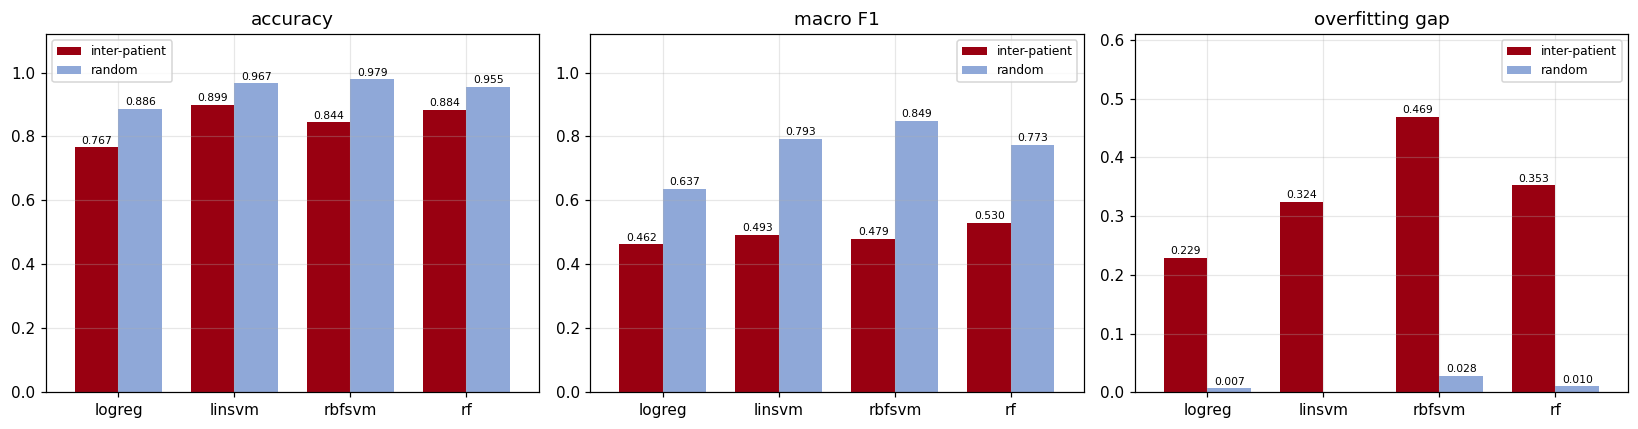

In [20]:
order = ["logreg", "linsvm", "rbfsvm", "rf"]
piv_acc = metrics.pivot(index="model", columns="split", values="accuracy").reindex(order)
piv_f1  = metrics.pivot(index="model", columns="split", values="f1_macro").reindex(order)
piv_gap = metrics.pivot(index="model", columns="split", values="overfit_gap").reindex(order)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, piv, title in zip(ax, [piv_acc, piv_f1, piv_gap],
                         ["accuracy", "macro F1", "overfitting gap"]):
    piv.plot.bar(ax=a, color=[SPLIT_COL[c] for c in piv.columns], width=0.75)
    a.set_title(title); a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
    a.legend(fontsize=8)
    for cont in a.containers:
        a.bar_label(cont, fmt="%.3f", fontsize=7, padding=1)
ax[0].set_ylim(0, 1.12); ax[1].set_ylim(0, 1.12)
ax[2].set_ylim(0, max(piv_gap.max().max()*1.3, 0.1))
plt.tight_layout()
save_fig(fig, "07_model_comparison")

        split best_model class          meaning  precision  recall    f1  support
       random     rbfsvm     N           Normal      0.997   0.981 0.989    22522
       random     rbfsvm     S Supraventricular      0.814   0.922 0.865      695
       random     rbfsvm     V      Ventricular      0.958   0.976 0.967     1752
       random     rbfsvm     F           Fusion      0.423   0.900 0.576      201
inter-patient         rf     N           Normal      0.961   0.911 0.935    44240
inter-patient         rf     S Supraventricular      0.166   0.207 0.185     1837
inter-patient         rf     V      Ventricular      0.816   0.971 0.887     3220
inter-patient         rf     F           Fusion      0.069   0.296 0.112      388


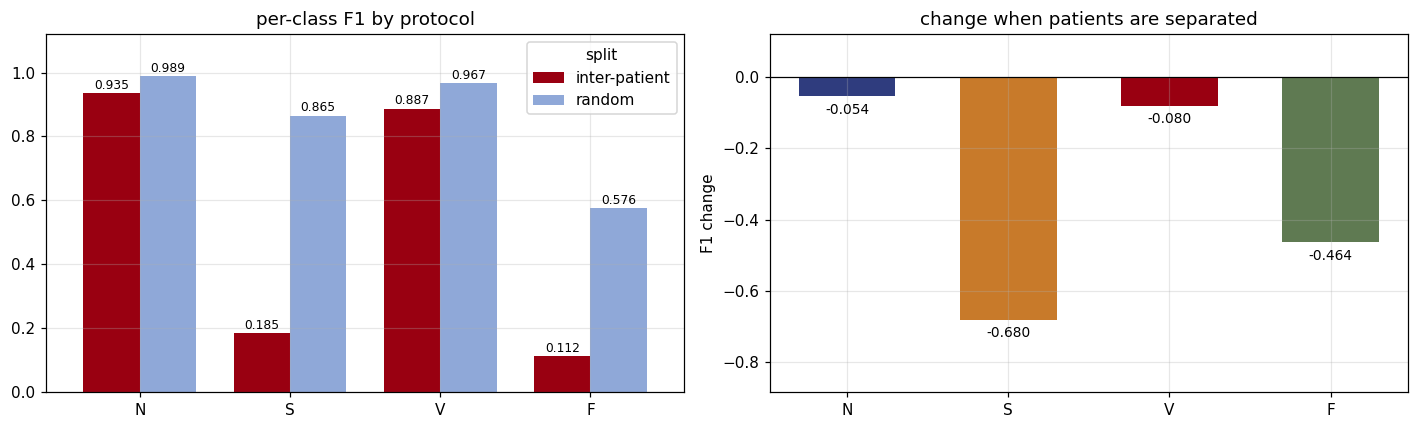

In [21]:
pc_rows = []
for split, pack in RES_MODELS.items():
    yte = pack["ytest"]
    name = max(pack["results"], key=lambda k: f1_score(yte, pack["results"][k]["pred"],
                                                       average="macro", labels=CLASSES, zero_division=0))
    p, rc, f1, sup = precision_recall_fscore_support(yte, pack["results"][name]["pred"],
                                                     labels=CLASSES, zero_division=0)
    for i, c in enumerate(CLASSES):
        pc_rows.append({"split": split, "best_model": name, "class": c,
                        "meaning": CLASS_NAME[c], "precision": round(p[i], 3),
                        "recall": round(rc[i], 3), "f1": round(f1[i], 3), "support": int(sup[i])})
per_class = pd.DataFrame(pc_rows)
save_table(per_class, "14_per_class_metrics")

piv_pc = per_class.pivot(index="class", columns="split", values="f1").reindex(CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
piv_pc.plot.bar(ax=ax[0], color=[SPLIT_COL[c] for c in piv_pc.columns], width=0.75)
ax[0].set_title("per-class F1 by protocol"); ax[0].set_ylim(0, 1.12)
ax[0].tick_params(axis="x", rotation=0); ax[0].set_xlabel("")
for cont in ax[0].containers:
    ax[0].bar_label(cont, fmt="%.3f", fontsize=8, padding=1)

delta = (piv_pc["inter-patient"] - piv_pc["random"])
ax[1].bar(delta.index, delta.values, color=[CLASS_COL[c] for c in delta.index], width=0.6)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_title("change when patients are separated")
ax[1].set_ylabel("F1 change")
for i, v in enumerate(delta.values):
    ax[1].text(i, v - 0.05 if v < 0 else v + 0.02, f"{v:+.3f}", ha="center", fontsize=9)
ax[1].set_ylim(delta.min()*1.3, 0.12)
plt.tight_layout()
save_fig(fig, "08_per_class_f1")

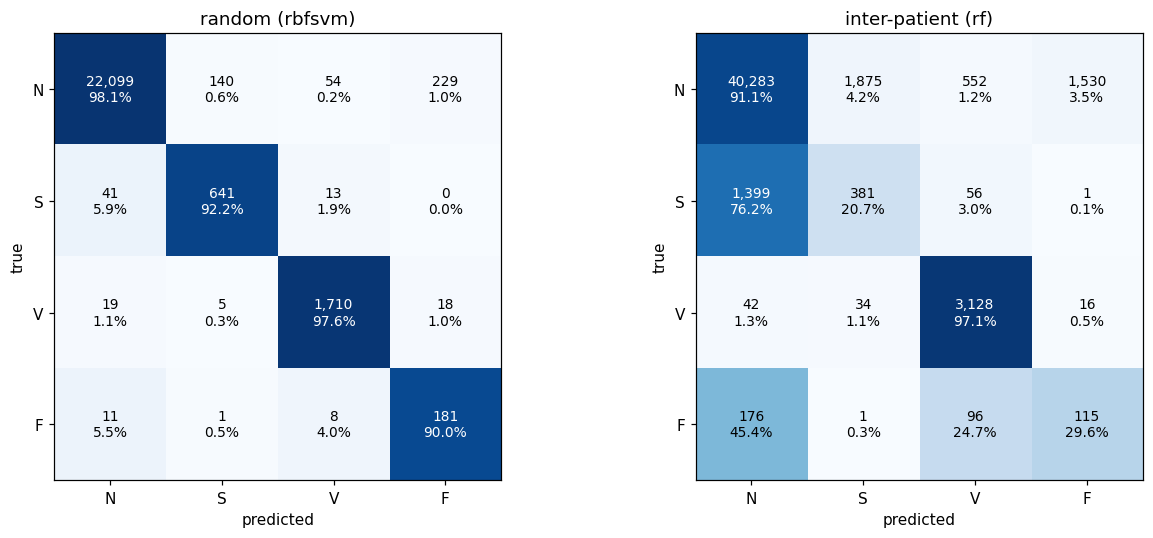

confusion matrices saved


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (split, pack) in zip(axes, RES_MODELS.items()):
    yte = pack["ytest"]
    name = max(pack["results"], key=lambda k: f1_score(yte, pack["results"][k]["pred"],
                                                       average="macro", labels=CLASSES, zero_division=0))
    cm  = confusion_matrix(yte, pack["results"][name]["pred"], labels=CLASSES)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for a in range(len(CLASSES)):
        for b in range(len(CLASSES)):
            ax.text(b, a, f"{cm[a,b]:,}\n{cmn[a,b]*100:.1f}%", ha="center", va="center",
                    fontsize=9, color="white" if cmn[a,b] > 0.5 else "black")
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{split} ({name})"); ax.grid(False)
plt.tight_layout()
save_fig(fig, "09_confusion_matrices")

cm_rows = []
for split, pack in RES_MODELS.items():
    yte = pack["ytest"]
    name = max(pack["results"], key=lambda k: f1_score(yte, pack["results"][k]["pred"],
                                                       average="macro", labels=CLASSES, zero_division=0))
    cm = confusion_matrix(yte, pack["results"][name]["pred"], labels=CLASSES)
    for i, tc in enumerate(CLASSES):
        for j, pc in enumerate(CLASSES):
            cm_rows.append({"split": split, "true": tc, "predicted": pc, "beats": int(cm[i, j])})
save_table(pd.DataFrame(cm_rows), "15_confusion_matrix", show=False)
print("confusion matrices saved")

## 11. Feature importance

Impurity-based importance from the random forest trained on the inter-patient split,
aggregated by feature family.

In [23]:
FAM_OF = {c: k for k, v in FAMILIES.items() if k != "ALL" for c in v}
FAM_COL = {"rr": "#2F3C7E", "morph": "#C87A2A", "wavelet": "#990011", "stats": "#5F7A52"}

rf_best = RES_MODELS["inter-patient"]["results"]["rf"]["model"].named_steps["clf"]
imp = pd.DataFrame({"feature": FEATURES,
                    "family": [FAM_OF[c] for c in FEATURES],
                    "importance": rf_best.feature_importances_.round(5)})
imp = imp.sort_values("importance", ascending=False).reset_index(drop=True)
imp["rank"] = imp.index + 1
save_table(imp.head(20)[["rank","feature","family","importance"]], "16_top_features")

fam_imp = (imp.groupby("family")["importance"].agg(["sum","count","mean"])
             .rename(columns={"sum":"total_importance","count":"n_features","mean":"mean_importance"})
             .sort_values("total_importance", ascending=False).round(5).reset_index())
fam_imp["importance_per_feature_rank"] = fam_imp["mean_importance"].rank(ascending=False).astype(int)
save_table(fam_imp, "17_family_importance")

 rank           feature  family  importance
    1   pre_over_global      rr     0.08353
    2            pre_rr      rr     0.07299
    3         global_rr      rr     0.06699
    4    pre_over_local      rr     0.06070
    5     post_over_pre      rr     0.04548
    6           morph31   morph     0.04499
    7              kurt   stats     0.03587
    8            w3_std wavelet     0.03465
    9           min_amp   stats     0.03017
   10           morph30   morph     0.02901
   11         rpeak_amp   stats     0.02869
   12         w2_energy wavelet     0.02800
   13           post_rr      rr     0.02799
   14            w2_std wavelet     0.02593
   15         w4_energy wavelet     0.02566
   16         w3_energy wavelet     0.02539
   17          local_rr      rr     0.02281
   18 local_over_global      rr     0.02088
   19         w0_energy wavelet     0.01706
   20           morph11   morph     0.01573
 family  total_importance  n_features  mean_importance  importance_per_featu

,family,total_importance,n_features,mean_importance,importance_per_feature_rank
0,rr,0.40137,8,0.05017,1
1,morph,0.30416,32,0.00950,4
2,wavelet,0.18352,13,0.01412,3
3,stats,0.11095,6,0.01849,2


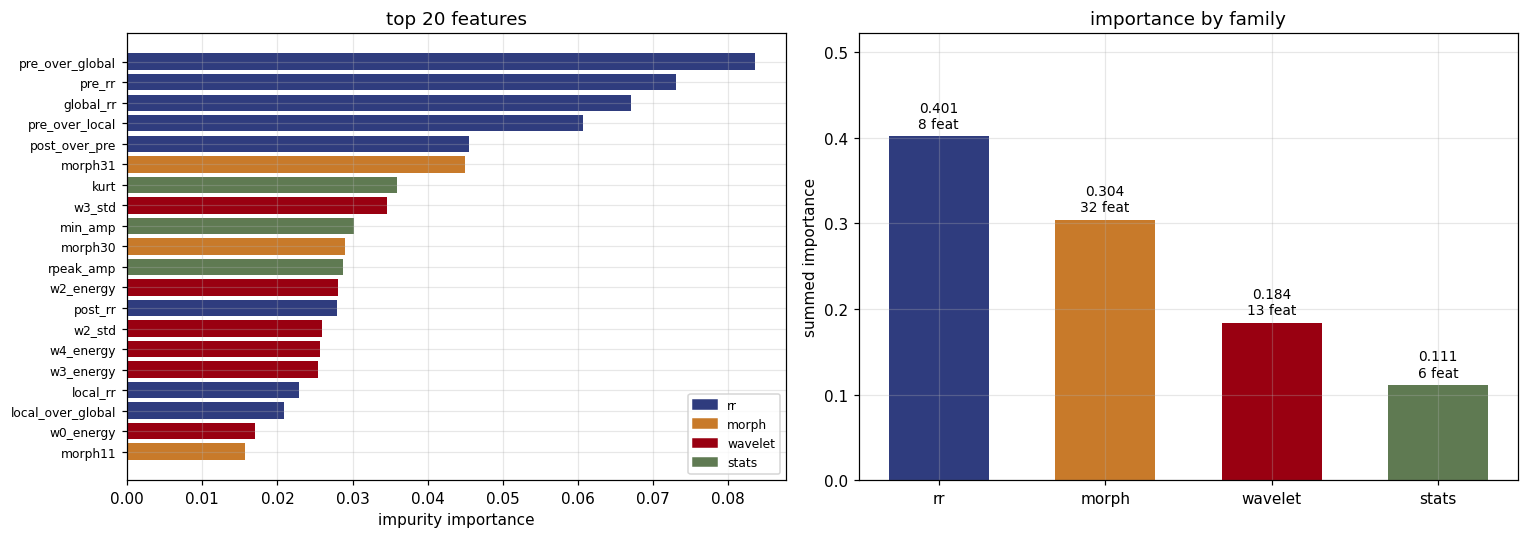

In [24]:
top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(top["feature"], top["importance"], color=[FAM_COL[f] for f in top["family"]])
ax[0].set_xlabel("impurity importance"); ax[0].set_title("top 20 features")
ax[0].tick_params(axis="y", labelsize=8)
hs = [plt.Rectangle((0,0),1,1,color=FAM_COL[f]) for f in FAM_COL]
ax[0].legend(hs, list(FAM_COL), fontsize=8, loc="lower right")

ax[1].bar(fam_imp["family"], fam_imp["total_importance"],
          color=[FAM_COL[f] for f in fam_imp["family"]], width=0.6)
for i, r in fam_imp.iterrows():
    ax[1].text(i, r["total_importance"]+0.01,
               f"{r['total_importance']:.3f}\n{int(r['n_features'])} feat", ha="center", fontsize=9)
ax[1].set_ylabel("summed importance"); ax[1].set_title("importance by family")
ax[1].set_ylim(0, fam_imp["total_importance"].max()*1.3)
plt.tight_layout()
save_fig(fig, "10_feature_importance")

## 12. Feature family ablation

Each family trained alone, on the inter-patient split, with one fixed forest. Importance
says which features the forest *used*; ablation says which features actually *carry* the
information.

In [25]:
def quick_rf(cols, tr, te, trees=200, depth=None, leaf=1, sampler=None,
             weight="balanced_subsample", y_override=None):
    ci = [FEATURES.index(c) for c in cols]
    y_src = y_all if y_override is None else y_override
    Xtr, ytr = X_all[np.ix_(tr, ci)], y_src[tr]
    if sampler is not None:
        Xtr, ytr = sampler.fit_resample(Xtr, ytr)
    m = RandomForestClassifier(n_estimators=trees, max_depth=depth, min_samples_leaf=leaf,
                               class_weight=weight, n_jobs=-1, random_state=SEED)
    m.fit(Xtr, ytr)
    pred = m.predict(X_all[np.ix_(te, ci)])
    yte  = y_src[te]
    per  = f1_score(yte, pred, average=None, labels=CLASSES, zero_division=0)
    return {"f1_macro": round(f1_score(yte, pred, average="macro", labels=CLASSES, zero_division=0), 4),
            "accuracy": round(accuracy_score(yte, pred), 4),
            **{"f1_" + c: round(per[i], 4) for i, c in enumerate(CLASSES)},
            "n_train": len(ytr), "pred": pred}

tr_i, te_i = split_interpatient()
tr_s = subsample(tr_i)

abl = []
for fam in ["rr", "morph", "wavelet", "stats", "ALL"]:
    r = quick_rf(FAMILIES[fam], tr_s, te_i)
    r.pop("pred")
    r.pop("n_train")
    abl.append({"family": fam, "n_features": len(FAMILIES[fam]), **r})
    print(f"  {fam:<8} macro F1 {r['f1_macro']:.4f}")
abl = pd.DataFrame(abl)
save_table(abl, "18_family_ablation")

  rr       macro F1 0.4369
  morph    macro F1 0.4126
  wavelet  macro F1 0.3670
  stats    macro F1 0.3826
  ALL      macro F1 0.4908
 family  n_features  f1_macro  accuracy   f1_N   f1_S   f1_V   f1_F
     rr           8    0.4369    0.9004 0.9545 0.0906 0.6981 0.0044
  morph          32    0.4126    0.9200 0.9604 0.0033 0.6869 0.0000
wavelet          13    0.3670    0.9075 0.9510 0.0084 0.5044 0.0042
  stats           6    0.3826    0.9097 0.9531 0.0010 0.5761 0.0000
    ALL          59    0.4908    0.9463 0.9710 0.0702 0.9221 0.0000


,family,n_features,f1_macro,accuracy,f1_N,f1_S,f1_V,f1_F
0,rr,8,0.4369,0.9004,0.9545,0.0906,0.6981,0.0044
1,morph,32,0.4126,0.9200,0.9604,0.0033,0.6869,0.0000
2,wavelet,13,0.3670,0.9075,0.9510,0.0084,0.5044,0.0042
3,stats,6,0.3826,0.9097,0.9531,0.0010,0.5761,0.0000
4,ALL,59,0.4908,0.9463,0.9710,0.0702,0.9221,0.0000


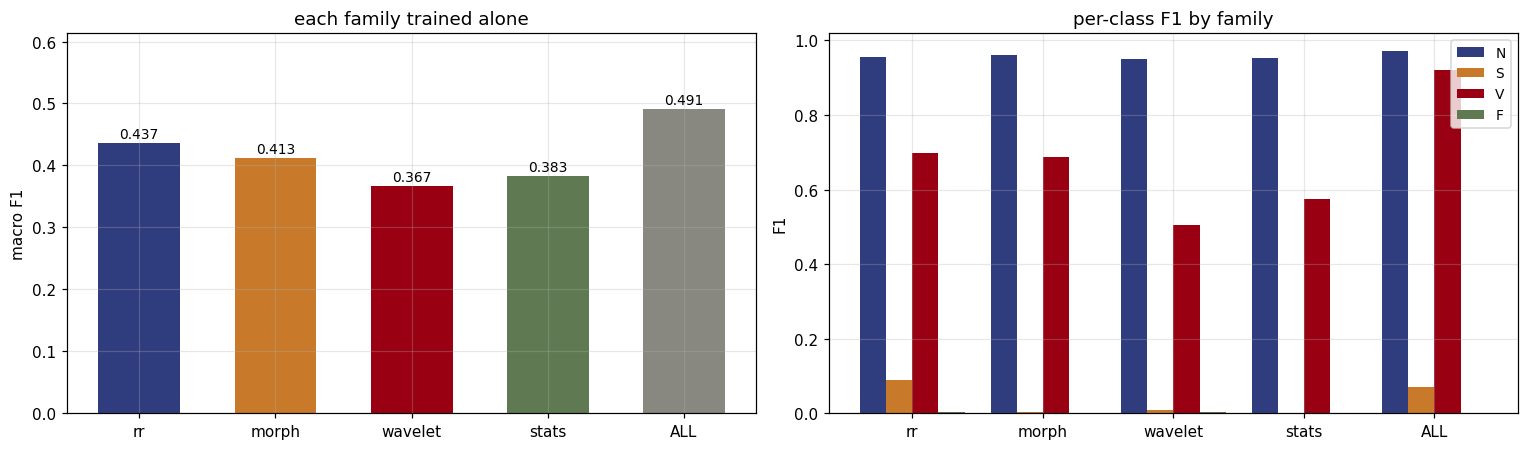

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(abl["family"], abl["f1_macro"],
          color=[FAM_COL.get(f, "#888780") for f in abl["family"]], width=0.6)
for i, v in enumerate(abl["f1_macro"]):
    ax[0].text(i, v+0.008, f"{v:.3f}", ha="center", fontsize=9)
ax[0].set_ylabel("macro F1"); ax[0].set_title("each family trained alone")
ax[0].set_ylim(0, abl["f1_macro"].max()*1.25)

w, xs = 0.2, np.arange(len(abl))
for i, c in enumerate(CLASSES):
    ax[1].bar(xs + i*w - 1.5*w, abl["f1_" + c], width=w, color=CLASS_COL[c], label=c)
ax[1].set_xticks(xs); ax[1].set_xticklabels(abl["family"])
ax[1].set_ylabel("F1"); ax[1].set_title("per-class F1 by family")
ax[1].legend(fontsize=9)
plt.tight_layout()
save_fig(fig, "11_family_ablation")

## 13. Feature combination study

Families are not additive. This measures whether adding a family helps or hurts.

In [27]:
COMBOS = {
    "rr":                 FAMILIES["rr"],
    "morph":              FAMILIES["morph"],
    "rr+stats":           FAMILIES["rr"] + FAMILIES["stats"],
    "rr+wavelet":         FAMILIES["rr"] + FAMILIES["wavelet"],
    "rr+morph":           FAMILIES["rr"] + FAMILIES["morph"],
    "rr+wavelet+stats":   FAMILIES["rr"] + FAMILIES["wavelet"] + FAMILIES["stats"],
    "morph+wavelet":      FAMILIES["morph"] + FAMILIES["wavelet"],
    "ALL":                FAMILIES["ALL"],
}

comb = []
for name, cols in COMBOS.items():
    r = quick_rf(cols, tr_s, te_i); r.pop("pred")
    r.pop("n_train")
    comb.append({"combination": name, "n_features": len(cols), **r})
    print(f"  {name:<18} macro F1 {r['f1_macro']:.4f}   F1(S) {r['f1_S']:.4f}")
comb = pd.DataFrame(comb).sort_values("f1_macro", ascending=False).reset_index(drop=True)
save_table(comb, "19_feature_combinations")

best_c = comb.iloc[0]
all_c  = comb[comb.combination == "ALL"].iloc[0]
verdict = pd.DataFrame([
    {"question": "Best combination", "answer": best_c["combination"],
     "f1_macro": best_c["f1_macro"], "f1_S": best_c["f1_S"]},
    {"question": "Using every feature", "answer": "ALL",
     "f1_macro": all_c["f1_macro"], "f1_S": all_c["f1_S"]},
    {"question": "Cost of adding the rest",
     "answer": f"{all_c['f1_macro'] - best_c['f1_macro']:+.4f} macro F1",
     "f1_macro": np.nan, "f1_S": round(all_c["f1_S"] - best_c["f1_S"], 4)},
])
save_table(verdict, "20_combination_verdict")

  rr                 macro F1 0.4369   F1(S) 0.0906
  morph              macro F1 0.4126   F1(S) 0.0033
  rr+stats           macro F1 0.5105   F1(S) 0.1559
  rr+wavelet         macro F1 0.5207   F1(S) 0.1982
  rr+morph           macro F1 0.4668   F1(S) 0.0772
  rr+wavelet+stats   macro F1 0.5209   F1(S) 0.1794
  morph+wavelet      macro F1 0.4252   F1(S) 0.0022
  ALL                macro F1 0.4908   F1(S) 0.0702
     combination  n_features  f1_macro  accuracy   f1_N   f1_S   f1_V   f1_F
rr+wavelet+stats          27    0.5209    0.9341 0.9655 0.1794 0.9321 0.0066
      rr+wavelet          21    0.5207    0.9156 0.9552 0.1982 0.9220 0.0076
        rr+stats          14    0.5105    0.9357 0.9658 0.1559 0.9203 0.0000
             ALL          59    0.4908    0.9463 0.9710 0.0702 0.9221 0.0000
        rr+morph          40    0.4668    0.9380 0.9700 0.0772 0.8201 0.0000
              rr           8    0.4369    0.9004 0.9545 0.0906 0.6981 0.0044
   morph+wavelet          45    0.4252    0.9

,question,answer,f1_macro,f1_S
0,Best combination,rr+wavelet+stats,0.5209,0.1794
1,Using every feature,ALL,0.4908,0.0702
2,Cost of adding the rest,-0.0301 macro F1,NaN,-0.1092


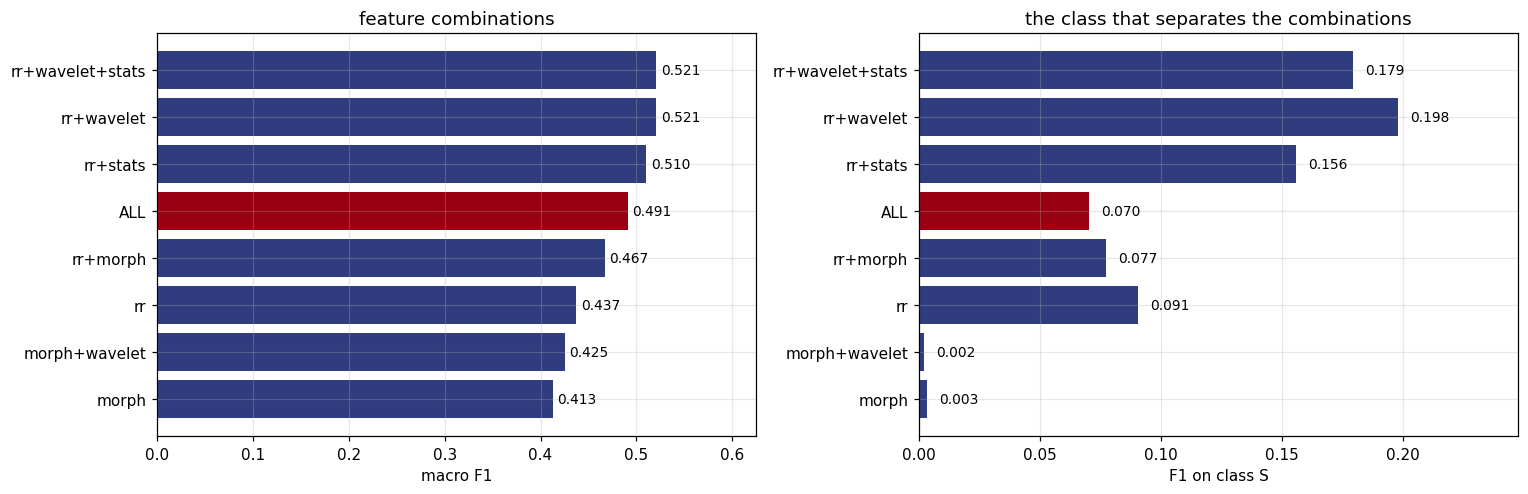

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
cb = comb.sort_values("f1_macro")
cols = ["#990011" if c == "ALL" else "#2F3C7E" for c in cb["combination"]]
ax[0].barh(cb["combination"], cb["f1_macro"], color=cols)
for i, v in enumerate(cb["f1_macro"]):
    ax[0].text(v+0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax[0].set_xlabel("macro F1"); ax[0].set_title("feature combinations")
ax[0].set_xlim(0, cb["f1_macro"].max()*1.2)

ax[1].barh(cb["combination"], cb["f1_S"], color=cols)
for i, v in enumerate(cb["f1_S"]):
    ax[1].text(v+0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax[1].set_xlabel("F1 on class S"); ax[1].set_title("the class that separates the combinations")
ax[1].set_xlim(0, max(cb["f1_S"].max()*1.25, 0.05))
plt.tight_layout()
save_fig(fig, "12_feature_combinations")

## 14. Is class imbalance the cause

The usual explanation for poor minority performance is imbalance. This tests it directly by
rebalancing the training set four different ways and measuring what changes.

In [29]:
IMB = {
    "none (class_weight off)":   (None, None),
    "class_weight balanced":     (None, "balanced_subsample"),
    "random oversample":         (RandomOverSampler(random_state=SEED), None),
    "SMOTE":                     (SMOTE(random_state=SEED, k_neighbors=5), None),
    "random undersample":        (RandomUnderSampler(random_state=SEED), None),
}

imb = []
for name, (samp, weight) in IMB.items():
    r = quick_rf(FEATURES, tr_s, te_i, sampler=samp, weight=weight)
    r.pop("pred")
    ratio = "1:1" if samp is not None else f"{(y_all[tr_s]=='N').sum()//max((y_all[tr_s]=='F').sum(),1)}:1"
    imb.append({"strategy": name, "train_rows": r.pop("n_train"),
                "N_to_F_ratio": ratio, **r})
    print(f"  {name:<26} macro F1 {r['f1_macro']:.4f}   F1(S) {r['f1_S']:.4f}")
imb = pd.DataFrame(imb)
save_table(imb, "21_imbalance_experiment")

spread = imb["f1_S"].max() - imb["f1_S"].min()
base   = imb[imb.strategy == "class_weight balanced"]["f1_S"].iloc[0]
iv = pd.DataFrame([
    {"finding": "Spread in F1(S) across all five strategies", "value": round(spread, 4)},
    {"finding": "Spread in macro F1 across all five strategies",
     "value": round(imb["f1_macro"].max() - imb["f1_macro"].min(), 4)},
    {"finding": "Best F1(S) achieved by any balancing",
     "value": f"{imb['f1_S'].max():.4f} ({imb.loc[imb.f1_S.idxmax(),'strategy']})"},
    {"finding": "F1(S) from feature choice instead (section 13)",
     "value": f"{comb['f1_S'].max():.4f} ({comb.loc[comb.f1_S.idxmax(),'combination']})"},
    {"finding": "Conclusion",
     "value": "imbalance is not the bottleneck" if spread < 0.05 else "imbalance matters"},
])
save_table(iv, "22_imbalance_verdict")

  none (class_weight off)    macro F1 0.4915   F1(S) 0.1715
  class_weight balanced      macro F1 0.4908   F1(S) 0.0702
  random oversample          macro F1 0.5019   F1(S) 0.1087
  SMOTE                      macro F1 0.5134   F1(S) 0.1773
  random undersample         macro F1 0.5204   F1(S) 0.1687
               strategy  train_rows N_to_F_ratio  f1_macro  accuracy   f1_N   f1_S   f1_V   f1_F
none (class_weight off)       25000        110:1    0.4915    0.9254 0.9592 0.1715 0.8352 0.0000
  class_weight balanced       25000        110:1    0.4908    0.9463 0.9710 0.0702 0.9221 0.0000
      random oversample       89908          1:1    0.5019    0.9452 0.9707 0.1087 0.9284 0.0000
                  SMOTE       89908          1:1    0.5134    0.9140 0.9530 0.1773 0.9220 0.0013
     random undersample         812          1:1    0.5204    0.8190 0.8932 0.1687 0.8850 0.1344
                                       finding               value
    Spread in F1(S) across all five strategies     

,finding,value
0,Spread in F1(S) across all five strategies,0.1071
1,Spread in macro F1 across all five strategies,0.0296
2,Best F1(S) achieved by any balancing,0.1773 (SMOTE)
3,F1(S) from feature choice instead (section 13),0.1982 (rr+wavelet)
4,Conclusion,imbalance matters


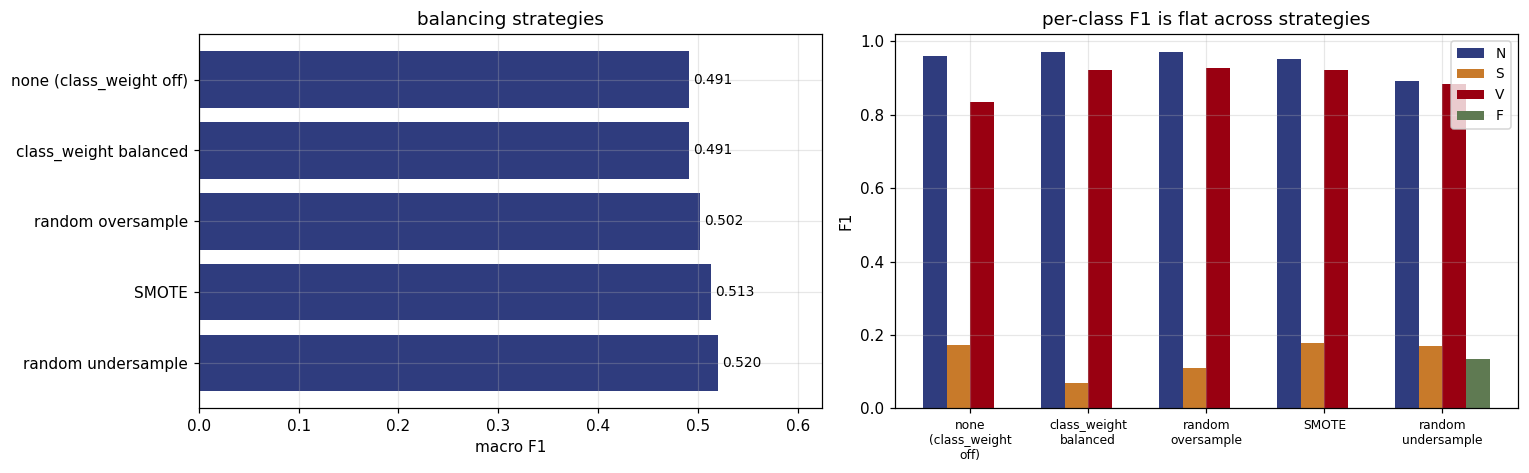

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ib = imb.iloc[::-1]
ax[0].barh(ib["strategy"], ib["f1_macro"], color="#2F3C7E")
for i, v in enumerate(ib["f1_macro"]):
    ax[0].text(v+0.004, i, f"{v:.3f}", va="center", fontsize=9)
ax[0].set_xlabel("macro F1"); ax[0].set_title("balancing strategies")
ax[0].set_xlim(0, ib["f1_macro"].max()*1.2)

w, xs = 0.2, np.arange(len(imb))
for i, c in enumerate(CLASSES):
    ax[1].bar(xs + i*w - 1.5*w, imb["f1_" + c], width=w, color=CLASS_COL[c], label=c)
ax[1].set_xticks(xs)
ax[1].set_xticklabels([s.replace(" ", "\n") for s in imb["strategy"]], fontsize=8)
ax[1].set_ylabel("F1"); ax[1].set_title("per-class F1 is flat across strategies")
ax[1].legend(fontsize=9)
plt.tight_layout()
save_fig(fig, "13_imbalance_experiment")

## 15. Learning curve

Does the model need more beats, or more patients? The curve answers the first question; the
flatness answers the second.

    1250 beats -> test macro F1 0.4675
    2500 beats -> test macro F1 0.4945
    5000 beats -> test macro F1 0.4938
   10000 beats -> test macro F1 0.4976
   17500 beats -> test macro F1 0.4915
   25000 beats -> test macro F1 0.4908
 fraction  train_beats  train_patients  train_f1  test_f1  test_acc   f1_S   f1_V    gap
     0.05         1250              22       1.0   0.4675    0.9434 0.0022 0.8986 0.5325
     0.10         2500              22       1.0   0.4945    0.9458 0.0827 0.9247 0.5055
     0.20         5000              22       1.0   0.4938    0.9472 0.0758 0.9279 0.5062
     0.40        10000              22       1.0   0.4976    0.9479 0.0845 0.9338 0.5024
     0.70        17500              22       1.0   0.4915    0.9448 0.0848 0.9110 0.5085
     1.00        25000              22       1.0   0.4908    0.9463 0.0702 0.9221 0.5092


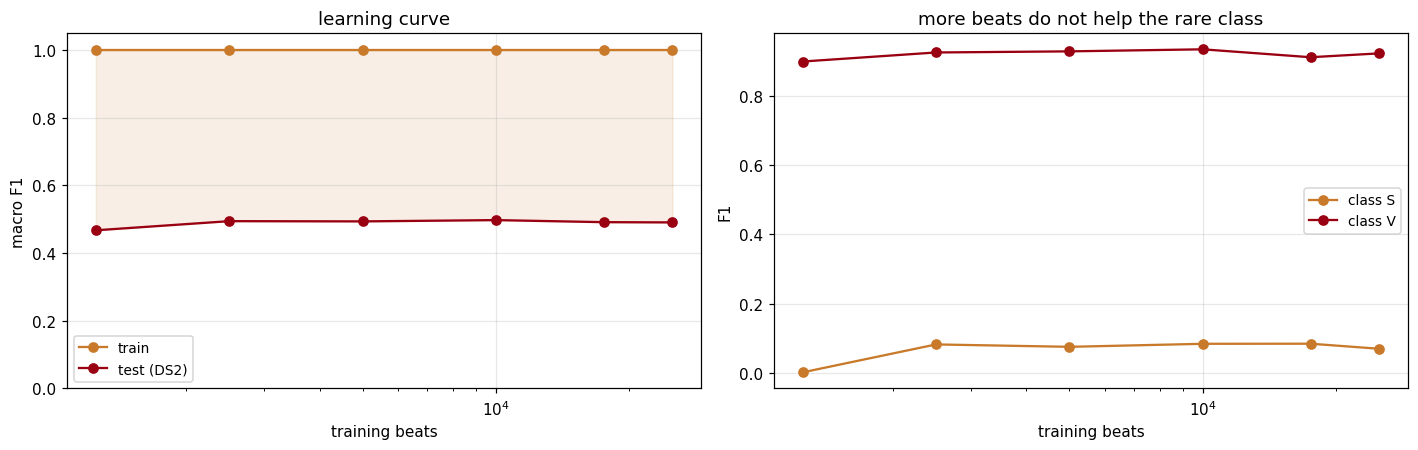

data_increase  macro_f1_gain  f1_S_gain  patients_gain
          20x         0.0233      0.068              0


,data_increase,macro_f1_gain,f1_S_gain,patients_gain
0,20x,0.0233,0.068,0


In [31]:
FRACS = [0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
lc = []
for f in FRACS:
    n = max(int(len(tr_s)*f), 200)
    sub = tr_s if f == 1.0 else subsample(tr_s, n)
    r = quick_rf(FEATURES, sub, te_i); r.pop("pred")
    ntr_f = quick_rf(FEATURES, sub, sub)
    lc.append({"fraction": f, "train_beats": len(sub),
               "train_patients": len(set(g_all[sub])),
               "train_f1": ntr_f["f1_macro"], "test_f1": r["f1_macro"],
               "test_acc": r["accuracy"], "f1_S": r["f1_S"], "f1_V": r["f1_V"]})
    print(f"  {len(sub):>6} beats -> test macro F1 {r['f1_macro']:.4f}")
lc = pd.DataFrame(lc)
lc["gap"] = (lc["train_f1"] - lc["test_f1"]).round(4)
save_table(lc, "23_learning_curve")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(lc["train_beats"], lc["train_f1"], "o-", color="#C87A2A", label="train")
ax[0].plot(lc["train_beats"], lc["test_f1"], "o-", color="#990011", label="test (DS2)")
ax[0].fill_between(lc["train_beats"], lc["test_f1"], lc["train_f1"], color="#C87A2A", alpha=0.12)
ax[0].set_xscale("log"); ax[0].set_xlabel("training beats"); ax[0].set_ylabel("macro F1")
ax[0].set_title("learning curve"); ax[0].legend(fontsize=9); ax[0].set_ylim(0, 1.05)

for c, col in [("f1_S", CLASS_COL["S"]), ("f1_V", CLASS_COL["V"])]:
    ax[1].plot(lc["train_beats"], lc[c], "o-", color=col, label=c.replace("f1_", "class "))
ax[1].set_xscale("log"); ax[1].set_xlabel("training beats"); ax[1].set_ylabel("F1")
ax[1].set_title("more beats do not help the rare class"); ax[1].legend(fontsize=9)
plt.tight_layout()
save_fig(fig, "14_learning_curve")

gain = pd.DataFrame([{
    "data_increase": f"{lc['train_beats'].iloc[-1]/lc['train_beats'].iloc[0]:.0f}x",
    "macro_f1_gain": round(lc["test_f1"].iloc[-1] - lc["test_f1"].iloc[0], 4),
    "f1_S_gain":     round(lc["f1_S"].iloc[-1] - lc["f1_S"].iloc[0], 4),
    "patients_gain": int(lc["train_patients"].iloc[-1] - lc["train_patients"].iloc[0]),
}])
save_table(gain, "24_learning_curve_gain")

## 16. Validation curves

Two knobs swept separately: tree depth, which controls how closely the forest can memorise,
and tree count, which controls variance only.

In [32]:
DEPTHS = [2, 4, 6, 8, 12, None]
vc = []
for d in DEPTHS:
    te_r = quick_rf(FEATURES, tr_s, te_i, depth=d)
    tr_r = quick_rf(FEATURES, tr_s, tr_s, depth=d)
    vc.append({"max_depth": "None" if d is None else d,
               "train_f1": tr_r["f1_macro"], "test_f1": te_r["f1_macro"],
               "gap": round(tr_r["f1_macro"] - te_r["f1_macro"], 4),
               "f1_S": te_r["f1_S"], "accuracy": te_r["accuracy"]})
    print(f"  depth {str(d):<5} train {tr_r['f1_macro']:.4f}  test {te_r['f1_macro']:.4f}")
vc = pd.DataFrame(vc)
save_table(vc, "25_depth_curve")

TREES = [10, 50, 100, 200, 400]
tc = []
for n in TREES:
    te_r = quick_rf(FEATURES, tr_s, te_i, trees=n)
    tr_r = quick_rf(FEATURES, tr_s, tr_s, trees=n)
    tc.append({"n_estimators": n, "train_f1": tr_r["f1_macro"], "test_f1": te_r["f1_macro"],
               "gap": round(tr_r["f1_macro"] - te_r["f1_macro"], 4)})
tc = pd.DataFrame(tc)
save_table(tc, "26_tree_count_curve")

  depth 2     train 0.6230  test 0.5165
  depth 4     train 0.7868  test 0.5374
  depth 6     train 0.8832  test 0.5419
  depth 8     train 0.9512  test 0.5240
  depth 12    train 0.9919  test 0.5243
  depth None  train 1.0000  test 0.4908
max_depth  train_f1  test_f1    gap   f1_S  accuracy
        2    0.6230   0.5165 0.1065 0.1771    0.8024
        4    0.7868   0.5374 0.2494 0.1770    0.8526
        6    0.8832   0.5419 0.3413 0.1796    0.8760
        8    0.9512   0.5240 0.4272 0.1948    0.9117
       12    0.9919   0.5243 0.4676 0.1854    0.9416
     None    1.0000   0.4908 0.5092 0.0702    0.9463
 n_estimators  train_f1  test_f1    gap
           10    0.9954   0.4593 0.5361
           50    1.0000   0.4796 0.5204
          100    1.0000   0.4890 0.5110
          200    1.0000   0.4908 0.5092
          400    1.0000   0.4919 0.5081


,n_estimators,train_f1,test_f1,gap
0,10,0.9954,0.4593,0.5361
1,50,1.0000,0.4796,0.5204
2,100,1.0000,0.4890,0.5110
3,200,1.0000,0.4908,0.5092
4,400,1.0000,0.4919,0.5081


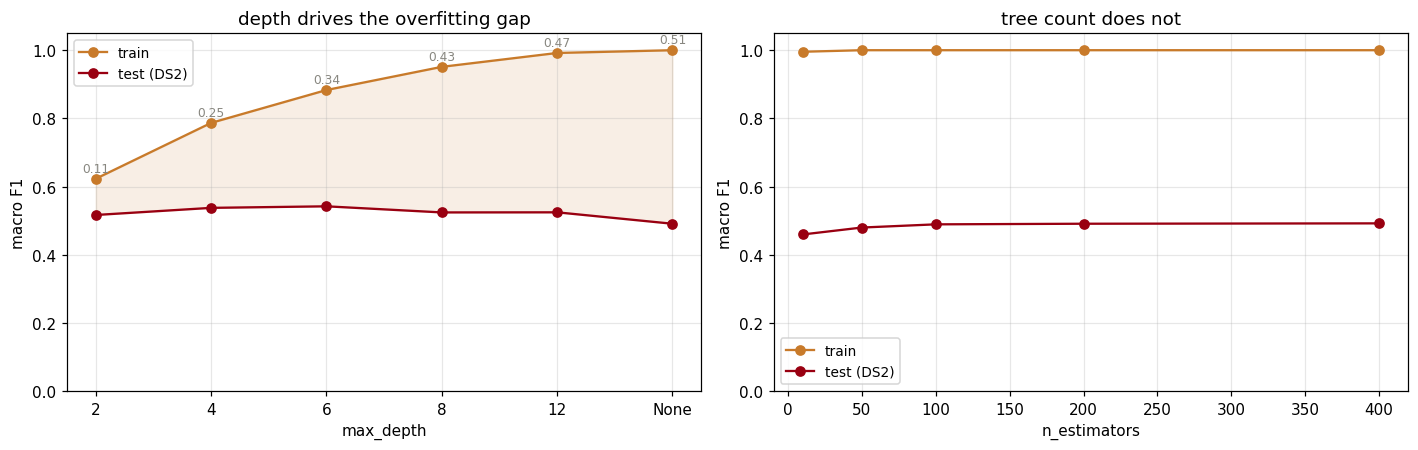

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
xs = range(len(vc))
ax[0].plot(xs, vc["train_f1"], "o-", color="#C87A2A", label="train")
ax[0].plot(xs, vc["test_f1"], "o-", color="#990011", label="test (DS2)")
ax[0].fill_between(xs, vc["test_f1"], vc["train_f1"], color="#C87A2A", alpha=0.12)
for i, g in enumerate(vc["gap"]):
    ax[0].text(i, vc["train_f1"].iloc[i]+0.02, f"{g:.2f}", ha="center", fontsize=8, color="#888780")
ax[0].set_xticks(list(xs)); ax[0].set_xticklabels(vc["max_depth"])
ax[0].set_xlabel("max_depth"); ax[0].set_ylabel("macro F1")
ax[0].set_title("depth drives the overfitting gap"); ax[0].legend(fontsize=9); ax[0].set_ylim(0, 1.05)

ax[1].plot(tc["n_estimators"], tc["train_f1"], "o-", color="#C87A2A", label="train")
ax[1].plot(tc["n_estimators"], tc["test_f1"], "o-", color="#990011", label="test (DS2)")
ax[1].set_xlabel("n_estimators"); ax[1].set_ylabel("macro F1")
ax[1].set_title("tree count does not"); ax[1].legend(fontsize=9); ax[1].set_ylim(0, 1.05)
plt.tight_layout()
save_fig(fig, "15_validation_curves")

## 17. Cross-validation

Five folds, grouped by patient, so every fold is itself an inter-patient test. The standard
deviation across folds is the honest uncertainty on the headline number.

  fold 1: macro F1 0.4494
  fold 2: macro F1 0.4308
  fold 3: macro F1 0.4811
  fold 4: macro F1 0.5930
  fold 5: macro F1 0.4868
fold  train_patients  test_patients  test_beats  f1_macro  accuracy   f1_N   f1_S   f1_V   f1_F
   1         35.0000         9.0000  20974.0000    0.4494    0.8863 0.9354 0.0212 0.8290 0.0119
   2         35.0000         9.0000  19408.0000    0.4308    0.9488 0.9757 0.0219 0.7256 0.0000
   3         34.0000        10.0000  22386.0000    0.4811    0.9500 0.9747 0.0865 0.8631 0.0000
   4         35.0000         9.0000  20101.0000    0.5930    0.9902 0.9950 0.4341 0.9429 0.0000
   5         37.0000         7.0000  17810.0000    0.4868    0.9554 0.9753 0.0571 0.9149 0.0000
mean         35.2000         8.8000  20135.8000    0.4882    0.9461 0.9712 0.1242 0.8551 0.0024
 std          1.0954         1.0954   1710.7183    0.0629    0.0375 0.0218 0.1754 0.0849 0.0053


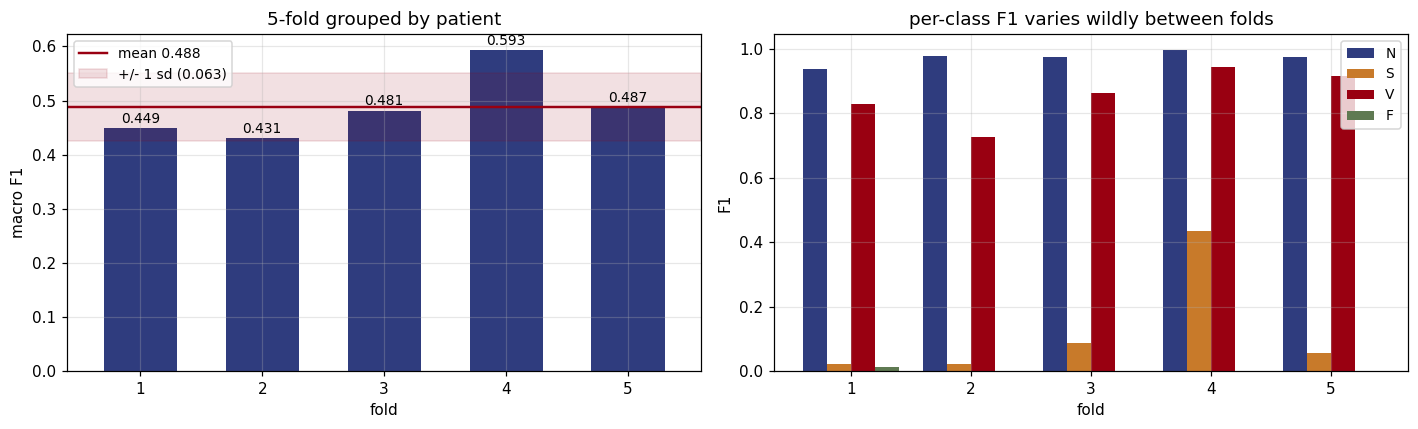

In [34]:
cvk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for k, (a, b) in enumerate(cvk.split(X_all, y_all, groups=g_all), 1):
    r = quick_rf(FEATURES, subsample(a), b); r.pop("pred")
    cv_rows.append({"fold": k, "train_patients": len(set(g_all[a])),
                    "test_patients": len(set(g_all[b])), "test_beats": len(b), **r})
    print(f"  fold {k}: macro F1 {r['f1_macro']:.4f}")
cv = pd.DataFrame(cv_rows).drop(columns=["n_train"])
summ = {"fold": "mean"}
for c in cv.columns[1:]:
    summ[c] = round(cv[c].mean(), 4)
sd = {"fold": "std"}
for c in cv.columns[1:]:
    sd[c] = round(cv[c].std(), 4)
cv = pd.concat([cv, pd.DataFrame([summ, sd])], ignore_index=True)
save_table(cv, "27_cross_validation")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
folds = cv[cv.fold.apply(lambda x: isinstance(x, int))]
m, s = summ["f1_macro"], sd["f1_macro"]
ax[0].bar(folds["fold"], folds["f1_macro"], color="#2F3C7E", width=0.6)
ax[0].axhline(m, color="#990011", lw=1.6, label=f"mean {m:.3f}")
ax[0].fill_between([0.4, 5.6], m-s, m+s, color="#990011", alpha=0.12, label=f"+/- 1 sd ({s:.3f})")
for i, v in zip(folds["fold"], folds["f1_macro"]):
    ax[0].text(i, v+0.01, f"{v:.3f}", ha="center", fontsize=9)
ax[0].set_xlabel("fold"); ax[0].set_ylabel("macro F1"); ax[0].set_xlim(0.4, 5.6)
ax[0].set_title("5-fold grouped by patient"); ax[0].legend(fontsize=9)

for i, c in enumerate(CLASSES):
    ax[1].bar(folds["fold"] + (i-1.5)*0.2, folds["f1_" + c], width=0.2,
              color=CLASS_COL[c], label=c)
ax[1].set_xlabel("fold"); ax[1].set_ylabel("F1")
ax[1].set_title("per-class F1 varies wildly between folds"); ax[1].legend(fontsize=9)
plt.tight_layout()
save_fig(fig, "16_cross_validation")

## 18. Per-record error analysis

The macro F1 is an average over patients that behave very differently. This locates the
failure.

In [35]:
best_name = max(RES_MODELS["inter-patient"]["results"],
                key=lambda k: f1_score(RES_MODELS["inter-patient"]["ytest"],
                                       RES_MODELS["inter-patient"]["results"][k]["pred"],
                                       average="macro", labels=CLASSES, zero_division=0))
pred_i = RES_MODELS["inter-patient"]["results"][best_name]["pred"]
dfe = pd.DataFrame({"record": g_all[te_i], "true": y_all[te_i], "pred": pred_i})

rec_rows = []
for rec, grp in dfe.groupby("record"):
    row = {"record": rec, "beats": len(grp),
           "accuracy": round((grp.true == grp.pred).mean(), 4)}
    for c in CLASSES:
        sub = grp[grp.true == c]
        row["n_" + c] = len(sub)
        row["recall_" + c] = round((sub.pred == c).mean(), 4) if len(sub) else np.nan
    rec_rows.append(row)
rec = pd.DataFrame(rec_rows).sort_values("accuracy")
save_table(rec, "28_per_record", show=False)
print(rec.head(10).to_string(index=False))

s_holders = (dfe[dfe.true == "S"].groupby("record").size()
               .sort_values(ascending=False).reset_index(name="S_beats"))
s_holders["share_of_DS2_S_pct"] = (100*s_holders["S_beats"]/s_holders["S_beats"].sum()).round(1)
s_holders = s_holders.merge(rec[["record","recall_S"]], on="record")
save_table(s_holders, "29_who_holds_class_S")

record  beats  accuracy  n_N  recall_N  n_S  recall_S  n_V  recall_V  n_F  recall_F
   232   1780    0.2292  398    0.9975 1382    0.0080    0       NaN    0       NaN
   233   3077    0.4514 2229    0.2544    7    0.0000  830    0.9855   11    0.3636
   222   2481    0.7283 2272    0.7064  209    0.9665    0       NaN    0       NaN
   202   2135    0.7719 2060    0.7694   55    0.8000   19    1.0000    1    0.0000
   219   2154    0.8305 2082    0.8295    7    0.2857   64    0.9375    1    0.0000
   210   2648    0.8637 2421    0.8674   22    0.5909  195    0.8923   10    0.0000
   213   3250    0.9086 2640    0.9962   28    0.1429  220    0.9455  362    0.3066
   221   2427    0.9114 2031    0.8946    0       NaN  396    0.9975    0       NaN
   105   2567    0.9525 2526    0.9521    0       NaN   41    0.9756    0       NaN
   200   2600    0.9685 1742    0.9765   30    0.9000  826    0.9564    2    0.0000
record  S_beats  share_of_DS2_S_pct  recall_S
   232     1382               

,record,S_beats,share_of_DS2_S_pct,recall_S
0,232,1382,75.2,0.0080
1,222,209,11.4,0.9665
2,202,55,3.0,0.8000
3,234,50,2.7,0.6600
4,100,33,1.8,1.0000
5,200,30,1.6,0.9000
6,213,28,1.5,0.1429
7,210,22,1.2,0.5909
8,233,7,0.4,0.0000
9,219,7,0.4,0.2857


              test_set  patients  beats  f1_macro   f1_S   f1_V
          DS2 complete        22  49685    0.4908 0.0702 0.9221
DS2 without record 232        21  47905    0.5374 0.2414 0.9224
                change        -1  -1780    0.0466 0.1712 0.0003


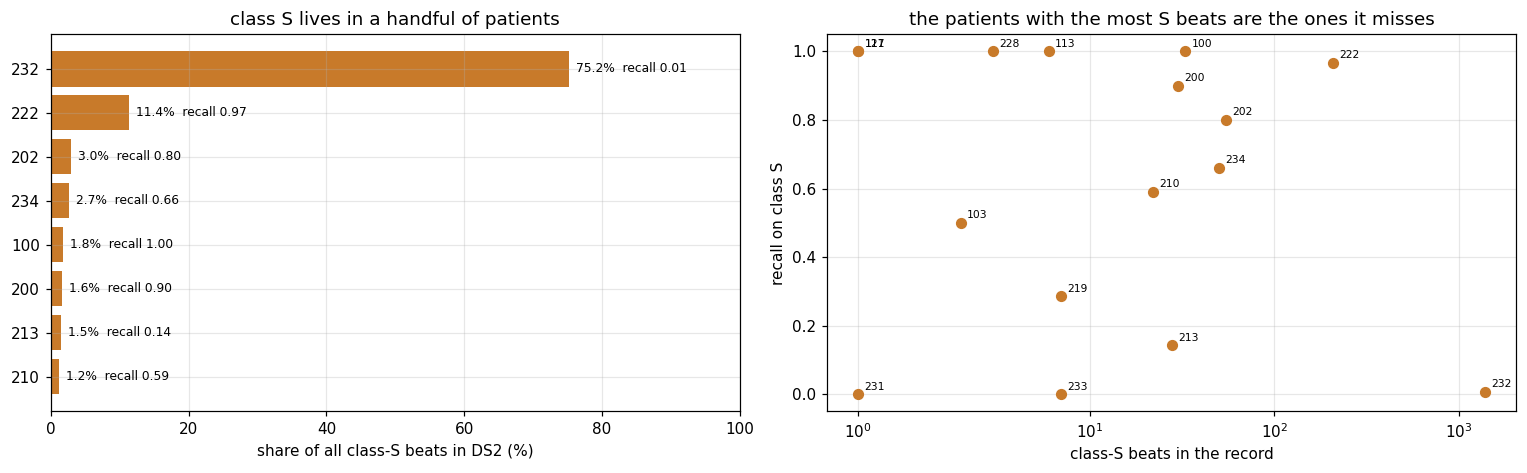

In [36]:
worst = s_holders.iloc[0]["record"]
keep_te = te_i[g_all[te_i] != worst]
r_with    = quick_rf(FEATURES, tr_s, te_i)
r_without = quick_rf(FEATURES, tr_s, keep_te)
excl = pd.DataFrame([
    {"test_set": "DS2 complete", "patients": len(set(g_all[te_i])), "beats": len(te_i),
     "f1_macro": r_with["f1_macro"], "f1_S": r_with["f1_S"], "f1_V": r_with["f1_V"]},
    {"test_set": f"DS2 without record {worst}", "patients": len(set(g_all[keep_te])),
     "beats": len(keep_te), "f1_macro": r_without["f1_macro"],
     "f1_S": r_without["f1_S"], "f1_V": r_without["f1_V"]},
    {"test_set": "change", "patients": -1, "beats": len(keep_te)-len(te_i),
     "f1_macro": round(r_without["f1_macro"]-r_with["f1_macro"], 4),
     "f1_S": round(r_without["f1_S"]-r_with["f1_S"], 4),
     "f1_V": round(r_without["f1_V"]-r_with["f1_V"], 4)},
])
save_table(excl, "30_single_patient_effect")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
sh = s_holders.head(8).iloc[::-1]
ax[0].barh(sh["record"].astype(str), sh["share_of_DS2_S_pct"], color=CLASS_COL["S"])
for i, r in enumerate(sh.itertuples()):
    ax[0].text(r.share_of_DS2_S_pct+1, i, f"{r.share_of_DS2_S_pct:.1f}%  recall {r.recall_S:.2f}",
               va="center", fontsize=8)
ax[0].set_xlabel("share of all class-S beats in DS2 (%)")
ax[0].set_title("class S lives in a handful of patients")
ax[0].set_xlim(0, 100)

rec_ok = rec.dropna(subset=["recall_S"])
ax[1].scatter(rec_ok["n_S"], rec_ok["recall_S"], s=40, color=CLASS_COL["S"], zorder=3)
for r in rec_ok.itertuples():
    ax[1].annotate(r.record, (r.n_S, r.recall_S), fontsize=7,
                   textcoords="offset points", xytext=(4, 3))
ax[1].set_xscale("symlog"); ax[1].set_xlabel("class-S beats in the record")
ax[1].set_ylabel("recall on class S"); ax[1].set_ylim(-0.05, 1.05)
ax[1].set_title("the patients with the most S beats are the ones it misses")
plt.tight_layout()
save_fig(fig, "17_per_record_analysis")

## 19. Honest model selection

Every number above was read off DS2, which means DS2 helped choose the configuration. The
honest procedure picks the configuration using DS1 only, then looks at DS2 exactly once.

  depth 2     DS1 inner CV 0.4459
  depth 4     DS1 inner CV 0.4633
  depth 6     DS1 inner CV 0.4295
  depth 8     DS1 inner CV 0.4131
  depth 12    DS1 inner CV 0.4089
  depth None  DS1 inner CV 0.3868
max_depth  DS1_inner_cv_f1  DS1_inner_cv_sd  DS2_f1
        2           0.4459           0.1321  0.5165
        4           0.4633           0.1192  0.5374
        6           0.4295           0.0870  0.5419
        8           0.4131           0.0704  0.5240
       12           0.4089           0.0668  0.5243
     None           0.3868           0.0812  0.4908
                                procedure max_depth  reported_f1
  Chosen on DS1 inner CV, reported on DS2         4       0.5374
   Chosen by reading DS2 (what not to do)         6       0.5419
Optimism from letting the test set choose                 0.0045


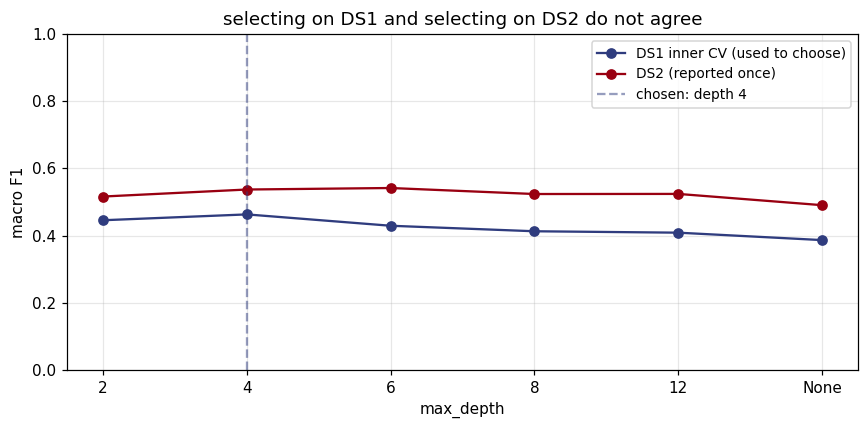

In [37]:
inner = StratifiedGroupKFold(n_splits=3)
hsel_rows = []
for d in DEPTHS:
    scores = []
    for a, b in inner.split(X_all[tr_s], y_all[tr_s], groups=g_all[tr_s]):
        r = quick_rf(FEATURES, tr_s[a], tr_s[b], depth=d)
        scores.append(r["f1_macro"])
    hsel_rows.append({"max_depth": "None" if d is None else d,
                     "DS1_inner_cv_f1": round(float(np.mean(scores)), 4),
                     "DS1_inner_cv_sd": round(float(np.std(scores)), 4)})
    print(f"  depth {str(d):<5} DS1 inner CV {np.mean(scores):.4f}")
hsel = pd.DataFrame(hsel_rows)
hsel = hsel.merge(vc[["max_depth","test_f1"]].rename(columns={"test_f1":"DS2_f1"}),
                  on="max_depth", how="left")
chosen  = hsel.loc[hsel["DS1_inner_cv_f1"].idxmax()]
peeking = hsel.loc[hsel["DS2_f1"].idxmax()]
save_table(hsel, "31_honest_selection")

bias = pd.DataFrame([
    {"procedure": "Chosen on DS1 inner CV, reported on DS2",
     "max_depth": chosen["max_depth"], "reported_f1": chosen["DS2_f1"]},
    {"procedure": "Chosen by reading DS2 (what not to do)",
     "max_depth": peeking["max_depth"], "reported_f1": peeking["DS2_f1"]},
    {"procedure": "Optimism from letting the test set choose",
     "max_depth": "", "reported_f1": round(peeking["DS2_f1"] - chosen["DS2_f1"], 4)},
])
save_table(bias, "32_selection_bias")

fig, ax = plt.subplots(figsize=(8, 4))
xs = range(len(hsel))
ax.plot(xs, hsel["DS1_inner_cv_f1"], "o-", color="#2F3C7E", label="DS1 inner CV (used to choose)")
ax.plot(xs, hsel["DS2_f1"], "o-", color="#990011", label="DS2 (reported once)")
ax.axvline(list(hsel["max_depth"]).index(chosen["max_depth"]), color="#2F3C7E",
           ls="--", alpha=0.5, label=f"chosen: depth {chosen['max_depth']}")
ax.set_xticks(list(xs)); ax.set_xticklabels(hsel["max_depth"])
ax.set_xlabel("max_depth"); ax.set_ylabel("macro F1")
ax.set_title("selecting on DS1 and selecting on DS2 do not agree")
ax.legend(fontsize=9); ax.set_ylim(0, 1.0)
plt.tight_layout()
save_fig(fig, "18_honest_selection")

## 20. Three-class variant

Class F has 388 training beats spread over a few patients. Dropping it gives the N/S/V task
that much of the published literature actually reports.

class          meaning  precision  recall    f1  support
    N           Normal      0.955   0.995 0.975    44240
    S Supraventricular      0.670   0.032 0.061     1837
    V      Ventricular      0.935   0.900 0.917     3220
MACRO                       0.853   0.643 0.651    49297
               task  classes  macro_f1
4 classes (N/S/V/F)        4    0.5298
  3 classes (N/S/V)        3    0.6511
         difference       -1    0.1213


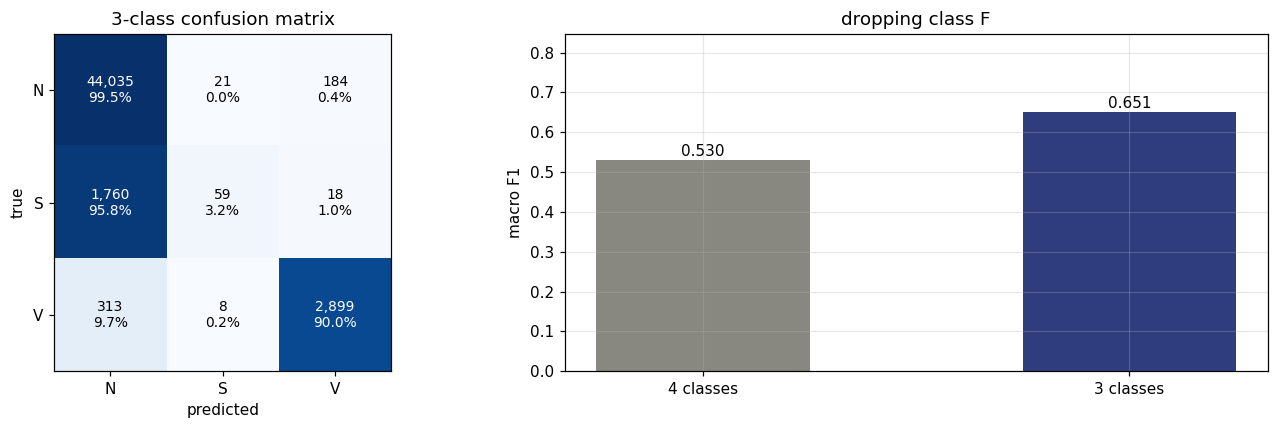

In [38]:
CL3 = ["N", "S", "V"]
m3  = np.isin(y_all, CL3)
tr3 = np.array([i for i in tr_s if m3[i]])
te3 = np.array([i for i in te_i if m3[i]])

ci = list(range(len(FEATURES)))
m = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                           n_jobs=-1, random_state=SEED)
m.fit(X_all[np.ix_(tr3, ci)], y_all[tr3])
p3 = m.predict(X_all[np.ix_(te3, ci)])

pr, rc, f1v, sup = precision_recall_fscore_support(y_all[te3], p3, labels=CL3, zero_division=0)
three = pd.DataFrame({"class": CL3, "meaning": [CLASS_NAME[c] for c in CL3],
                      "precision": pr.round(3), "recall": rc.round(3),
                      "f1": f1v.round(3), "support": sup})
three.loc[len(three)] = ["MACRO", "", round(pr.mean(), 3), round(rc.mean(), 3),
                         round(f1v.mean(), 3), sup.sum()]
save_table(three, "33_three_class")

four_macro = metrics[(metrics.split=="inter-patient") & (metrics.model==best_name)]["f1_macro"].iloc[0]
cmp3 = pd.DataFrame([
    {"task": "4 classes (N/S/V/F)", "classes": 4, "macro_f1": four_macro},
    {"task": "3 classes (N/S/V)",   "classes": 3, "macro_f1": round(f1v.mean(), 4)},
    {"task": "difference", "classes": -1, "macro_f1": round(f1v.mean() - four_macro, 4)},
])
save_table(cmp3, "34_three_vs_four")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cm3  = confusion_matrix(y_all[te3], p3, labels=CL3)
cm3n = cm3 / cm3.sum(axis=1, keepdims=True)
ax[0].imshow(cm3n, cmap="Blues", vmin=0, vmax=1)
for a in range(3):
    for b in range(3):
        ax[0].text(b, a, f"{cm3[a,b]:,}\n{cm3n[a,b]*100:.1f}%", ha="center", va="center",
                   fontsize=9, color="white" if cm3n[a,b] > 0.5 else "black")
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(CL3)
ax[0].set_yticks(range(3)); ax[0].set_yticklabels(CL3)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
ax[0].set_title("3-class confusion matrix"); ax[0].grid(False)

ax[1].bar(["4 classes", "3 classes"], [four_macro, f1v.mean()],
          color=["#888780", "#2F3C7E"], width=0.5)
for i, v in enumerate([four_macro, f1v.mean()]):
    ax[1].text(i, v+0.01, f"{v:.3f}", ha="center", fontsize=10)
ax[1].set_ylabel("macro F1"); ax[1].set_title("dropping class F")
ax[1].set_ylim(0, max(four_macro, f1v.mean())*1.3)
plt.tight_layout()
save_fig(fig, "19_three_class")

## 21. Pipeline validation

Three sanity checks. If the pipeline cannot fail these, none of the numbers above mean
anything.

                   baseline  f1_macro  accuracy  beats_always_N_by
           Always predict N    0.2355    0.8904             0.0000
             Uniform random    0.1435    0.2499            -0.0920
    Random from class prior    0.2496    0.8055             0.0141
Labels shuffled in training    0.2355    0.8904             0.0000
                 Real model    0.4908    0.9463             0.2553


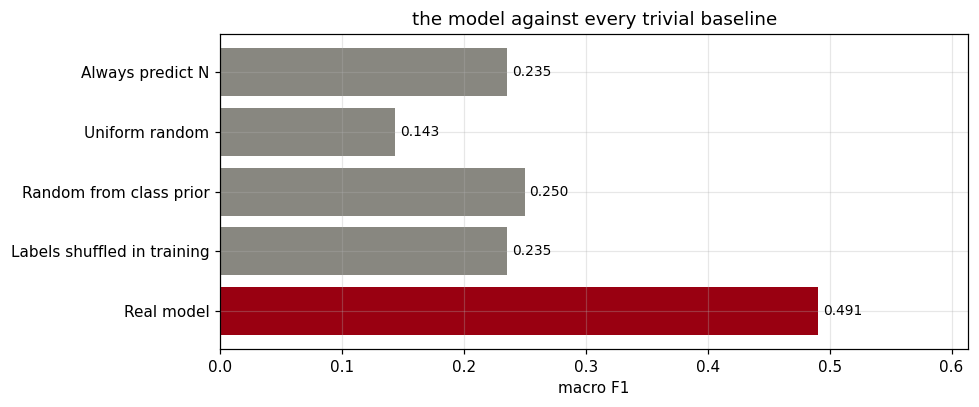

In [39]:
rng = np.random.default_rng(SEED)
y_shuf = y_all.copy()
y_shuf[tr_s] = rng.permutation(y_all[tr_s])
r_shuf = quick_rf(FEATURES, tr_s, te_i, y_override=y_shuf)

maj  = np.full(len(te_i), pd.Series(y_all[tr_s]).mode()[0])
rnd  = rng.choice(CLASSES, size=len(te_i))
prior = pd.Series(y_all[tr_s]).value_counts(normalize=True)
strat = rng.choice(prior.index.values, size=len(te_i), p=prior.values)
real  = quick_rf(FEATURES, tr_s, te_i)

def sc(pred):
    return (round(f1_score(y_all[te_i], pred, average="macro", labels=CLASSES, zero_division=0), 4),
            round(accuracy_score(y_all[te_i], pred), 4))

base = pd.DataFrame([
    {"baseline": "Always predict N",        "f1_macro": sc(maj)[0],   "accuracy": sc(maj)[1]},
    {"baseline": "Uniform random",          "f1_macro": sc(rnd)[0],   "accuracy": sc(rnd)[1]},
    {"baseline": "Random from class prior", "f1_macro": sc(strat)[0], "accuracy": sc(strat)[1]},
    {"baseline": "Labels shuffled in training", "f1_macro": r_shuf["f1_macro"],
     "accuracy": r_shuf["accuracy"]},
    {"baseline": "Real model",              "f1_macro": real["f1_macro"], "accuracy": real["accuracy"]},
])
base["beats_always_N_by"] = (base["f1_macro"] - sc(maj)[0]).round(4)
save_table(base, "35_pipeline_validation")

fig, ax = plt.subplots(figsize=(9, 3.8))
b = base.iloc[::-1]
cols = ["#990011" if s == "Real model" else "#888780" for s in b["baseline"]]
ax.barh(b["baseline"], b["f1_macro"], color=cols)
for i, v in enumerate(b["f1_macro"]):
    ax.text(v+0.004, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("macro F1"); ax.set_title("the model against every trivial baseline")
ax.set_xlim(0, b["f1_macro"].max()*1.25)
plt.tight_layout()
save_fig(fig, "20_pipeline_validation")

## 22. Summary of findings

Every row is a number produced above, with the table and figure it came from.

In [40]:
mi = metrics[metrics.split == "inter-patient"].sort_values("f1_macro", ascending=False).iloc[0]
mr = metrics[(metrics.split == "random") & (metrics.model == mi["model"])].iloc[0]
pc_i = per_class[per_class.split == "inter-patient"].set_index("class")
pc_r = per_class[per_class.split == "random"].set_index("class")
rr_f1S  = abl[abl.family == "rr"]["f1_S"].iloc[0]
oth_f1S = abl[abl.family.isin(["morph","wavelet","stats"])]["f1_S"].max()
best_cb = comb.iloc[0]
all_cb  = comb[comb.combination == "ALL"].iloc[0]
cv_mean = cv[cv.fold == "mean"]["f1_macro"].iloc[0]
cv_sd   = cv[cv.fold == "std"]["f1_macro"].iloc[0]
deep    = vc[vc.max_depth == "None"].iloc[0]
shallow = vc[vc.max_depth == 4].iloc[0]

findings = pd.DataFrame([
    {"n": 1, "finding": "Best model under the honest protocol",
     "evidence": f"{mi['model']}: accuracy {mi['accuracy']:.4f}, macro F1 {mi['f1_macro']:.4f}, kappa {mi['kappa']:.4f}",
     "table": "13_model_metrics", "figure": "07_model_comparison"},
    {"n": 2, "finding": "Accuracy hides the failure; macro F1 does not",
     "evidence": f"accuracy falls {(mr['accuracy']-mi['accuracy'])*100:+.1f} pts between protocols, macro F1 falls {(mr['f1_macro']-mi['f1_macro'])*100:+.1f} pts",
     "table": "13_model_metrics", "figure": "07_model_comparison"},
    {"n": 3, "finding": "Weighted F1 is accuracy wearing a different name",
     "evidence": f"weighted F1 {mi['f1_weighted']:.4f} vs accuracy {mi['accuracy']:.4f}, difference {abs(mi['f1_weighted']-mi['accuracy']):.4f}",
     "table": "13_model_metrics", "figure": "07_model_comparison"},
    {"n": 4, "finding": "Sharing patients between train and test inflates the rare classes",
     "evidence": f"F1(S) {pc_r.loc['S','f1']:.3f} -> {pc_i.loc['S','f1']:.3f}, F1(F) {pc_r.loc['F','f1']:.3f} -> {pc_i.loc['F','f1']:.3f}",
     "table": "14_per_class_metrics", "figure": "08_per_class_f1"},
    {"n": 5, "finding": "Class imbalance is not the bottleneck",
     "evidence": f"five balancing strategies move F1(S) by only {imb['f1_S'].max()-imb['f1_S'].min():.4f}",
     "table": "21_imbalance_experiment", "figure": "13_imbalance_experiment"},
    {"n": 6, "finding": "Only the timing features detect class S",
     "evidence": f"RR alone F1(S) {rr_f1S:.4f}, best of the other three families {oth_f1S:.4f}",
     "table": "18_family_ablation", "figure": "11_family_ablation"},
    {"n": 7, "finding": "Adding every feature is worse than choosing a subset",
     "evidence": f"{best_cb['combination']} macro F1 {best_cb['f1_macro']:.4f} vs ALL {all_cb['f1_macro']:.4f}",
     "table": "19_feature_combinations", "figure": "12_feature_combinations"},
    {"n": 8, "finding": "More beats do not help; more patients would",
     "evidence": f"{gain['data_increase'].iloc[0]} more training beats buys {gain['macro_f1_gain'].iloc[0]:+.4f} macro F1",
     "table": "23_learning_curve", "figure": "14_learning_curve"},
    {"n": 9, "finding": "Depth causes the overfitting, not tree count",
     "evidence": f"gap {shallow['gap']:.3f} at depth 4 vs {deep['gap']:.3f} unlimited; {tc['gap'].min():.3f} to {tc['gap'].max():.3f} across 10-400 trees",
     "table": "25_depth_curve", "figure": "15_validation_curves"},
    {"n": 10, "finding": "The result is one patient away from looking different",
     "evidence": f"excluding record {worst} changes F1(S) by {excl.iloc[2]['f1_S']:+.4f}",
     "table": "30_single_patient_effect", "figure": "17_per_record_analysis"},
    {"n": 11, "finding": "Choosing hyperparameters on the test set adds optimism",
     "evidence": f"{bias.iloc[2]['reported_f1']:+.4f} macro F1 from letting DS2 pick the depth",
     "table": "32_selection_bias", "figure": "18_honest_selection"},
    {"n": 12, "finding": "Fold-to-fold variation is larger than any tuning gain",
     "evidence": f"grouped 5-fold macro F1 {cv_mean:.4f} +/- {cv_sd:.4f}",
     "table": "27_cross_validation", "figure": "16_cross_validation"},
    {"n": 13, "finding": "The pipeline has no leakage of its own",
     "evidence": f"shuffled labels score {base[base.baseline.str.contains('shuffled')]['f1_macro'].iloc[0]:.4f} against the always-N baseline {base[base.baseline=='Always predict N']['f1_macro'].iloc[0]:.4f}",
     "table": "35_pipeline_validation", "figure": "20_pipeline_validation"},
    {"n": 14, "finding": "Dropping class F does not rescue the task",
     "evidence": f"3-class macro F1 {cmp3[cmp3.task=='3 classes (N/S/V)']['macro_f1'].iloc[0]:.4f} vs 4-class {four_macro:.4f}",
     "table": "34_three_vs_four", "figure": "19_three_class"},
])
save_table(findings, "36_summary_of_findings", show=False)
print(findings[["n","finding","evidence"]].to_string(index=False))

 n                                                           finding                                                                    evidence
 1                              Best model under the honest protocol                          rf: accuracy 0.8837, macro F1 0.5298, kappa 0.5197
 2                     Accuracy hides the failure; macro F1 does not         accuracy falls +7.1 pts between protocols, macro F1 falls +24.4 pts
 3                  Weighted F1 is accuracy wearing a different name                    weighted F1 0.8980 vs accuracy 0.8837, difference 0.0143
 4 Sharing patients between train and test inflates the rare classes                                  F1(S) 0.865 -> 0.185, F1(F) 0.576 -> 0.112
 5                             Class imbalance is not the bottleneck                         five balancing strategies move F1(S) by only 0.1071
 6                           Only the timing features detect class S              RR alone F1(S) 0.0906, best of the other three f

                                        lever  macro_f1_swing
Evaluation protocol (random vs inter-patient)          0.2437
              Feature subset (8 combinations)          0.1083
               Choice of algorithm (4 models)          0.0674
                        Tree depth (6 values)          0.0511
                       Tree count (10 to 400)          0.0326
               Class balancing (5 strategies)          0.0296


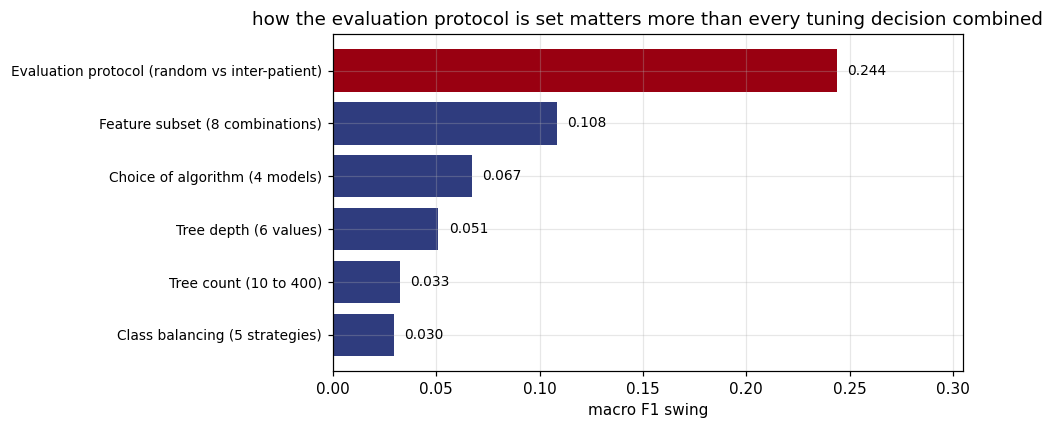

In [41]:
protocol_spread = abs(mr["f1_macro"] - mi["f1_macro"])
config_spread   = metrics[metrics.split == "inter-patient"]["f1_macro"].max() - \
                  metrics[metrics.split == "inter-patient"]["f1_macro"].min()
tuning_spread   = vc["test_f1"].max() - vc["test_f1"].min()

lever = pd.DataFrame([
    {"lever": "Evaluation protocol (random vs inter-patient)", "macro_f1_swing": round(protocol_spread, 4)},
    {"lever": "Choice of algorithm (4 models)",                "macro_f1_swing": round(config_spread, 4)},
    {"lever": "Feature subset (8 combinations)",               "macro_f1_swing": round(comb["f1_macro"].max()-comb["f1_macro"].min(), 4)},
    {"lever": "Tree depth (6 values)",                         "macro_f1_swing": round(tuning_spread, 4)},
    {"lever": "Class balancing (5 strategies)",                "macro_f1_swing": round(imb["f1_macro"].max()-imb["f1_macro"].min(), 4)},
    {"lever": "Tree count (10 to 400)",                        "macro_f1_swing": round(tc["test_f1"].max()-tc["test_f1"].min(), 4)},
]).sort_values("macro_f1_swing", ascending=False).reset_index(drop=True)
save_table(lever, "37_what_moves_the_result")

fig, ax = plt.subplots(figsize=(9, 4))
lv = lever.iloc[::-1]
cols = ["#990011" if i == len(lv)-1 else "#2F3C7E" for i in range(len(lv))]
ax.barh(lv["lever"], lv["macro_f1_swing"], color=cols)
for i, v in enumerate(lv["macro_f1_swing"]):
    ax.text(v+0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("macro F1 swing")
ax.set_title("how the evaluation protocol is set matters more than every tuning decision combined")
ax.set_xlim(0, lv["macro_f1_swing"].max()*1.25)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
save_fig(fig, "21_what_moves_the_result")

## 23. Save notebook, code and results

Everything lands under one project folder: the notebook in `notebook/`, the same pipeline as a
plain Python module in `code/`, every CSV in `results/tables/`, every PNG in
`results/figures/`, the documents in `results/`.

In [42]:
NB_NAME = "ECG_arrhythmia_classification.ipynb"
NB_PATH = os.path.join(NBDIR, NB_NAME)

def capture_notebook():
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        with open(NB_PATH, "w") as f:
            json.dump(nb, f, indent=1)
        return nb
    except Exception as e:
        print("could not capture the live notebook:", type(e).__name__, e)
        print("use File > Download > .ipynb and place it in", NBDIR)
        return None

nb_json = capture_notebook()
if nb_json is not None:
    print("saved", NB_PATH)
    print("cells:", len(nb_json["cells"]))

saved /content/drive/MyDrive/ecg_mitbih/project/notebook/ECG_arrhythmia_classification.ipynb
cells: 76


In [43]:
CODE = os.path.join(PROJ, "code")
os.makedirs(CODE, exist_ok=True)
CODE_PATH = os.path.join(CODE, "pipeline.py")
NOT_PIPELINE = ("drive.mount", "getpass", "subprocess", "capture_notebook",
                "_message.blocking_request", "shutil.copy", "export_code",
                "git(", "TOKEN", "CLONE")
STOP_AT = "23."
DOC = ['"""ECG arrhythmia classification pipeline.',
       "",
       "Generated from the notebook, so the module and the notebook cannot drift apart.",
       "Cells that only work inside Colab (Drive mount, GitHub push) are left out.",
       '"""', ""]

def export_code(nb):
    if nb is None:
        return 0
    body, n = list(DOC), 0
    for c in nb["cells"]:
        src = c["source"]
        src = src if isinstance(src, str) else "".join(src)
        if c["cell_type"] == "markdown":
            head = [l for l in src.splitlines() if l.startswith("#")]
            if head and head[0].lstrip("# ").startswith(STOP_AT):
                break
            if head:
                body += ["", "# " + "=" * 76, "# " + head[0].lstrip("# "),
                         "# " + "=" * 76, ""]
            continue
        if any(k in src for k in NOT_PIPELINE):
            continue
        body += [l for l in src.splitlines() if not l.lstrip().startswith("!")] + [""]
        n += 1
    with open(CODE_PATH, "w") as f:
        f.write(chr(10).join(body))
    return n

n_exported = export_code(nb_json)
print("code module:", CODE_PATH, "|", n_exported, "cells exported")

code module: /content/drive/MyDrive/ecg_mitbih/project/code/pipeline.py | 40 cells exported


In [44]:
tree_rows = []
for root, dirs, files in os.walk(PROJ):
    dirs[:] = sorted(d for d in dirs if not d.startswith("."))
    for f in sorted(files):
        if f.startswith("."):
            continue
        p = os.path.join(root, f)
        tree_rows.append({"folder": os.path.relpath(root, PROJ),
                          "file": f,
                          "kind": os.path.splitext(f)[1].lstrip(".") or "-",
                          "kb": round(os.path.getsize(p)/1024, 1)})
manifest = pd.DataFrame(tree_rows)
save_table(manifest, "38_file_manifest", show=False)

print("project root:", PROJ)
print()
print(manifest.groupby(["folder","kind"]).agg(files=("file","count"), total_kb=("kb","sum")).to_string())
print()
print("tables saved :", len([f for f in os.listdir(TAB) if f.endswith(".csv")]))
print("figures saved:", len([f for f in os.listdir(FIG) if f.endswith(".png")]))

project root: /content/drive/MyDrive/ecg_mitbih/project

                       files  total_kb
folder          kind                  
code            py         1      61.0
notebook        ipynb      1    1783.1
results/figures png       21    1574.1
results/tables  csv       37      14.9

tables saved : 38
figures saved: 21
